# Playground - Apartment Prices Prediction
by $\mathbb{JX}$

## Setup

In [1]:
import math
import re
import warnings
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from scipy.stats import gaussian_kde, t as t_dist

In [2]:
# plotting helpers for EDA
def plot_hist(df, col, log=False, bins=50):
    """Histogram of one numeric column; log=True plots log(1 + col)."""
    sl_plot = df[col].dropna()
    if log:
        sl_plot = np.log1p(sl_plot)
    label = f'log(1 + {col})' if log else col

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(sl_plot, bins=bins)
    ax.set_title(label)
    ax.set_xlabel(label)
    ax.set_ylabel('count')
    plt.show()

def plot_counts(df, l_cols, levels=None):
    """Bar chart of counts per level, one panel per column (shared y-axis), for discrete columns.
    levels: e.g. range(1, 11) to keep levels with zero houses on the x-axis."""
    fig, axes = plt.subplots(1, len(l_cols), figsize=(6 * len(l_cols), 4), sharey=True, squeeze=False)
    for ax, col in zip(axes.flat, l_cols):
        sl_counts = df[col].value_counts().sort_index()
        if levels is not None:
            sl_counts = sl_counts.reindex(levels, fill_value=0)
        ax.bar(sl_counts.index.astype(str), sl_counts.values)
        ax.set_title(col)
    axes[0, 0].set_ylabel('count')
    plt.tight_layout()
    plt.show()

def plot_boxes(df, l_cols, ncols=4):
    """One boxplot per column (own y-axis each, since scales differ)."""
    nrows = math.ceil(len(l_cols) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.5 * nrows), squeeze=False)
    for ax, col in zip(axes.flat, l_cols):
        ax.boxplot(df[col].dropna())
        ax.set_title(col)
        ax.set_xticks([])
    for ax in axes.flat[len(l_cols):]:  # hide unused panels
        ax.set_visible(False)
    plt.tight_layout()
    plt.show()

def plot_scatter(df, x, y, alpha=0.4):
    """Scatter of y against x, with their correlation in the title."""
    r = df[x].corr(df[y])

    fig, ax = plt.subplots(figsize=(6, 5))
    ax.scatter(df[x], df[y], alpha=alpha)
    ax.set_title(f'{y} vs {x}  (r = {r:.2f})')
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    plt.show()

def plot_densities(df, col, by, log=False, min_n=5, width=0.8):
    """Half-violin density (KDE) of col for each level of `by`, levels sorted by median; log=True plots log(1 + col).
    Groups with fewer than min_n rows are drawn as dots, since a KDE of a handful of points is meaningless."""
    sl_plot = np.log1p(df[col]) if log else df[col]
    label = f'log(1 + {col})' if log else col
    df_plot = pd.DataFrame({'y': sl_plot, 'g': df[by]}).dropna()
    l_levels = df_plot.groupby('g')['y'].median().sort_values().index
    n_by_level = df_plot['g'].value_counts()

    fig, ax = plt.subplots(figsize=(max(8, 0.6 * len(l_levels)), 5))
    for i, level in enumerate(l_levels):
        sl_g = df_plot.loc[df_plot['g'] == level, 'y']
        color = f'C{i % 10}'
        if len(sl_g) >= min_n:
            y_grid = np.linspace(sl_g.min(), sl_g.max(), 200)
            dens = gaussian_kde(sl_g)(y_grid)
            x = i + width * dens / dens.max()  # every group's peak gets the same width
            ax.plot(x, y_grid, color=color)
            ax.fill_betweenx(y_grid, i, x, color=color, alpha=0.2)
        else:
            ax.scatter(np.full(len(sl_g), i), sl_g, color=color, s=12)
        ax.plot([i, i + width], [sl_g.median()] * 2, color=color, linewidth=1, linestyle=':')  # group median
    ax.axhline(df_plot['y'].median(), color='red', linestyle='--', linewidth=1, label='overall median')
    ax.set_xticks(range(len(l_levels)), [f'{level} (n={n_by_level[level]})' for level in l_levels], rotation=90)
    ax.set_title(f'density of {label} by {by}, sorted by median')
    ax.set_xlabel(by)
    ax.set_ylabel(label)
    ax.legend()
    plt.tight_layout()
    plt.show()

def plot_box_strip(df, col, by, log=False, jitter=0.15, seed=0):
    """Boxplot of col for each level of `by` (sorted by median), with every row overlaid as a jittered dot; log=True plots log(1 + col)."""
    sl_plot = np.log1p(df[col]) if log else df[col]
    label = f'log(1 + {col})' if log else col
    df_plot = pd.DataFrame({'y': sl_plot, 'g': df[by]}).dropna()
    l_levels = df_plot.groupby('g')['y'].median().sort_values().index
    l_groups = [df_plot.loc[df_plot['g'] == level, 'y'] for level in l_levels]
    rng = np.random.default_rng(seed)  # fixed seed so the jitter doesn't move on every re-run

    fig, ax = plt.subplots(figsize=(max(8, 0.6 * len(l_levels)), 5))
    ax.boxplot(l_groups, positions=range(len(l_levels)), widths=0.6, showfliers=False)  # outliers already shown as dots
    for i, sl_g in enumerate(l_groups):
        ax.scatter(i + rng.uniform(-jitter, jitter, len(sl_g)), sl_g, s=6, alpha=0.4, color=f'C{i % 10}')
    ax.axhline(df_plot['y'].median(), color='red', linestyle='--', linewidth=1, label='overall median')
    ax.set_xticks(range(len(l_levels)), [f'{level} (n={len(sl_g)})' for level, sl_g in zip(l_levels, l_groups)], rotation=90)
    ax.set_title(f'{label} by {by}, sorted by median')
    ax.set_xlabel(by)
    ax.set_ylabel(label)
    ax.legend()
    plt.tight_layout()
    plt.show()

def plot_group_means(df, col, by, log=False, l_controls=None, level=0.95):
    """Mean of col for each level of `by` (sorted) with t-based confidence intervals, plus a joint F-test of
    H0: all group means are equal (regression on the group dummies, HC1-robust). With l_controls, the F-test is
    repeated holding those columns fixed. log=True uses log(col). Returns the table of group stats."""
    sl_y = np.log(df[col]) if log else df[col]
    label = f'log({col})' if log else col
    df_plot = pd.DataFrame({'y': sl_y, 'g': df[by]}).dropna()
    df_stats = df_plot.groupby('g')['y'].agg(['size', 'mean', 'std']).rename(columns={'size': 'n'})
    df_stats['se'] = df_stats['std'] / np.sqrt(df_stats['n'])
    df_stats['ci_half'] = t_dist.ppf((1 + level) / 2, df_stats['n'] - 1) * df_stats['se']  # t, not 1.96: small groups get wider CIs
    df_stats = df_stats.sort_values('mean')

    ## joint F-test: y on the group dummies (+ controls); H0 = every dummy coefficient is 0
    for l_ctrl in [[]] + ([l_controls] if l_controls else []):
        X = pd.get_dummies(df[by], prefix=by, drop_first=True, dtype=float)
        l_dummies = list(X.columns)
        X = sm.add_constant(pd.concat([X, df[l_ctrl]], axis=1))
        res = sm.OLS(sl_y, X, missing='drop').fit(cov_type='HC1')
        ft = res.f_test(np.eye(X.shape[1])[[X.columns.get_loc(c) for c in l_dummies]])
        ctrl_text = f'controlling for {l_ctrl}' if l_ctrl else 'no controls'
        print(f'{by} ({ctrl_text}): F = {np.squeeze(ft.fvalue):.1f} on {len(l_dummies)} dummies, p = {float(ft.pvalue):.2g}, R² = {res.rsquared:.3f}')

    fig, ax = plt.subplots(figsize=(max(8, 0.6 * len(df_stats)), 5))
    ax.errorbar(range(len(df_stats)), df_stats['mean'], yerr=df_stats['ci_half'], fmt='o', capsize=3)
    ax.axhline(df_plot['y'].mean(), color='red', linestyle='--', linewidth=1, label='overall mean')
    ax.set_xticks(range(len(df_stats)), [f'{g} (n={n})' for g, n in df_stats['n'].items()], rotation=90)
    ax.set_title(f'mean {label} by {by}, with {level:.0%} CIs, sorted')
    ax.set_xlabel(by)
    ax.set_ylabel(label)
    ax.legend()
    plt.tight_layout()
    plt.show()
    return df_stats.round(3)

In [3]:
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
# only the literal string "NA" becomes NaN: pandas' default would also turn MasVnrType's "None" (= no veneer) into NaN
read_kwargs = dict(keep_default_na=False, na_values=['NA'])
df_data = pd.read_csv(ROOT / "data" / "train.csv", **read_kwargs)
df_test = pd.read_csv(ROOT / "data" / "test.csv", **read_kwargs)

## Understanding the dataset + cleaning

In [4]:
df_data.duplicated().sum()  # 0

np.int64(0)

In [5]:
# NA summary across train AND test (features only), split by what NA means for each column
## columns where data_description.txt lists NA as a code, i.e. NA = feature absent (e.g. "NA  No Garage")
l_na_coded = []
col = None
for line in open(ROOT / "data" / "data_description.txt"):
    m = re.match(r'^(\w+):', line)  # column header line, e.g. "Alley: Type of alley access to property"
    if m:
        col = m.group(1)
    elif col and re.match(r'^\s+NA\s', line):  # indented value line for the code NA
        l_na_coded.append(col)

l_features = df_test.columns  # everything except SalePrice
na_summary = pd.DataFrame({
    "na_train": df_data[l_features].isna().sum(),
    "na_test": df_test.isna().sum(),
    "pct_na_train": round(df_data[l_features].isna().mean()*100, 2),
    "pct_na_test": round(df_test.isna().mean()*100, 2),
})
na_summary['na_means'] = np.where(na_summary.index.isin(l_na_coded), 'absent', 'MISSING')
na_summary = na_summary[(na_summary['na_train'] + na_summary['na_test']) > 0]
na_summary.sort_values(['na_means', 'na_train', 'na_test'], ascending=[True, False, False])

,na_train,na_test,pct_na_train,pct_na_test,na_means
LotFrontage,259,227,17.74,15.56,MISSING
GarageYrBlt,81,78,5.55,5.35,MISSING
MasVnrType,8,16,0.55,1.10,MISSING
MasVnrArea,8,15,0.55,1.03,MISSING
Electrical,1,0,0.07,0.00,MISSING
MSZoning,0,4,0.00,0.27,MISSING
Utilities,0,2,0.00,0.14,MISSING
BsmtFullBath,0,2,0.00,0.14,MISSING
BsmtHalfBath,0,2,0.00,0.14,MISSING
Functional,0,2,0.00,0.14,MISSING


### Cleaning NAs

Only the columns with NAs in train **or** test (see the NA summary above), one group at a time. Each decision is one of two kinds:
* **Kind A - fixed rules** (e.g. NA → `"None"` where the feature is absent, typo fixes, dropping a column): learn nothing from the data, so they go in a `clean_*(df)` function applied to train and test alike.
* **Kind B - learned values** (median / mode for genuinely missing values): recorded in `d_impute` (column → `SimpleImputer` strategy) and fitted inside the pipeline, so each CV fold learns them from its own training rows.

In [6]:
d_impute = {}  # column -> SimpleImputer strategy for genuinely missing values; filled in group by group below

#### 1. Garage

* Train: `GarageType` is NA exactly where `GarageArea` = 0 (81 rows) → no garage. Test matches, except 2 houses with a detached garage but missing details (Ids 2127, 2577).
* Test Id 2593: `GarageYrBlt` = 2207 (built 2006, remodelled 2007) → typo for 2007.

| # | Decision | Kind |
|---|---|---|
| 1 | `GarageType`/`Finish`/`Qual`/`Cond` NA where `GarageArea` = 0 → `"None"` | A |
| 2 | Drop `GarageYrBlt`: no sensible value for "no garage", and it equals `YearBuilt` in 79% of houses with a garage | A |
| 3 | Id 2593: `GarageYrBlt` 2207 → 2007 (moot while 2 drops the column) | A |
| 4 | Id 2127: missing `Finish`/`Qual`/`Cond` → mode | B |
| 5 | Id 2577: treat as having a garage; `Finish`/`Qual`/`Cond` → mode, `Cars`/`Area` → median | B |

In [7]:
# garage: kind-A rules (fixed, safe on train and test alike) + kind-B decisions (learned in the pipeline)
l_garage_cat = ['GarageType', 'GarageFinish', 'GarageQual', 'GarageCond']
l_garage_num = ['GarageCars', 'GarageArea']

def clean_garage(df):
    df = df.copy()
    no_garage = df['GarageArea'] == 0  # NaN area (test Id 2577) is NOT counted as "no garage"
    df.loc[no_garage, l_garage_cat] = df.loc[no_garage, l_garage_cat].fillna('None')  # 1. NA = no garage
    df['GarageYrBlt'] = df['GarageYrBlt'].replace(2207, 2007)  # 3. typo (test Id 2593); moot while 2. drops the column
    return df.drop(columns=['GarageYrBlt'])  # 2. mostly repeats YearBuilt (equal in 79% of houses with a garage)

# 4, 5(a). genuinely missing (test Ids 2127, 2577): imputed in the pipeline from the training data
d_impute.update({c: 'most_frequent' for c in ['GarageFinish', 'GarageQual', 'GarageCond']})
d_impute.update({c: 'median' for c in l_garage_num})

## check: rows still with NaNs after the kind-A rules = the genuinely missing ones
for name, df in [('train', df_data), ('test', df_test)]:
    df_c = clean_garage(df)
    df_left = df_c.loc[df_c[l_garage_cat + l_garage_num].isna().any(axis=1), ['Id'] + l_garage_cat + l_garage_num]
    print(f'{name}: {len(df_left)} rows left for the imputer')
    display(df_left)

train: 0 rows left for the imputer


,Id,GarageType,GarageFinish,GarageQual,GarageCond,GarageCars,GarageArea


test: 2 rows left for the imputer


,Id,GarageType,GarageFinish,GarageQual,GarageCond,GarageCars,GarageArea
666,2127,Detchd,NaN,NaN,NaN,1.0,360.0
1116,2577,Detchd,NaN,NaN,NaN,NaN,NaN


#### 2. Basement

* Train: all 37 houses with `TotalBsmtSF` = 0 have all 5 basement categoricals NA → no basement. Test: same for its 41, plus Id 2121, where *every* basement field is NA (the categoricals agree it has none). Test Id 2189 has no basement but NA bath counts.
* Genuinely missing (house has a basement): train 949 (`Exposure`), 333 (`FinType2`); test 1488, 2349 (`Exposure`), 2218, 2219 (`Qual`), 2041, 2186, 2525 (`Cond`).

| # | Decision | Kind |
|---|---|---|
| 1 | No basement (`TotalBsmtSF` = 0, or every basement field NA): 5 categoricals → `"None"`, SF and bath counts → 0 | A |
| 2 | Remaining categorical NAs → mode | B |
| 3 | Id 333's `BsmtFinType2` → plain mode (`Unf`) | B |

On 3: strictly, `Unf` contradicts Id 333's `BsmtFinSF2` = 479 (a second *finished* area). The more correct fill would be the mode among houses with `BsmtFinSF2` > 0, but that's a conditional rule `SimpleImputer` can't do. It's the only such conflict (one training row, none in test), so the plain mode is kept for simplicity; the effect on the model should be negligible.

In [8]:
# basement: kind-A rules (fixed, safe on train and test alike) + kind-B decisions (learned in the pipeline)
l_bsmt_cat = ['BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2']
l_bsmt_num = ['BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath']

def clean_basement(df):
    df = df.copy()
    no_bsmt = (df['TotalBsmtSF'] == 0) | df[l_bsmt_cat + l_bsmt_num].isna().all(axis=1)  # 2nd part: test Id 2121, every basement field NA
    df.loc[no_bsmt, l_bsmt_cat] = df.loc[no_bsmt, l_bsmt_cat].fillna('None')  # 1. NA = no basement
    df.loc[no_bsmt, l_bsmt_num] = df.loc[no_bsmt, l_bsmt_num].fillna(0)  # 1. no basement = 0 sq ft, 0 baths
    return df

# 2, 3(a). genuinely missing categoricals (houses that do have a basement): mode, imputed in the pipeline
d_impute.update({c: 'most_frequent' for c in l_bsmt_cat})

## check: rows still with NaNs after the kind-A rules = the genuinely missing ones
for name, df in [('train', df_data), ('test', df_test)]:
    df_c = clean_basement(df)
    df_left = df_c.loc[df_c[l_bsmt_cat + l_bsmt_num].isna().any(axis=1), ['Id'] + l_bsmt_cat + ['TotalBsmtSF']]
    print(f'{name}: {len(df_left)} rows left for the imputer')
    display(df_left)

train: 2 rows left for the imputer


,Id,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2,TotalBsmtSF
332,333,Gd,TA,No,GLQ,NaN,3206
948,949,Gd,TA,NaN,Unf,Unf,936


test: 7 rows left for the imputer


,Id,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2,TotalBsmtSF
27,1488,Gd,TA,NaN,Unf,Unf,1595.0
580,2041,Gd,NaN,Mn,GLQ,Rec,1426.0
725,2186,TA,NaN,No,BLQ,Unf,1127.0
757,2218,NaN,Fa,No,Unf,Unf,173.0
758,2219,NaN,TA,No,Unf,Unf,356.0
888,2349,Gd,TA,NaN,Unf,Unf,725.0
1064,2525,TA,NaN,Av,ALQ,Unf,995.0


#### 3. Masonry veneer

* Both columns NA: 8 train, 15 test. Test Id 2611: type NA but area 198.
* Contradictions: `"None"` with area 1 (train 774, 1231; test 2453 - a placeholder), `"None"` with real area (train 625, 1301, 1335; test 1670), type set with area 0 (train 689, 1242; test 2320).

One principle: **trust the area**.

| # | Decision | Kind |
|---|---|---|
| 1 | Both NA → type mode, area median (on train: `"None"`, 0 = no veneer) | B |
| 2 | Area ≤ 1 → type `"None"`, area 0 | A |
| 3 | Area > 1 but type `"None"`/NA → `"BrkFace"` (most common veneer type in train: 445 vs Stone 128) | A |

Unlike basement Id 333, a plain mode for 3 would leave contradictions in *test* rows (1670, 2611), which feed straight into their predictions.

In [9]:
# masonry veneer: kind-A rules ("trust the area") + kind-B decisions (learned in the pipeline)
l_mvnr = ['MasVnrType', 'MasVnrArea']

def clean_masonry(df):
    df = df.copy()
    no_vnr = df['MasVnrArea'] <= 1  # 2. area 0, or a 1-sq-ft placeholder = no veneer (NaN area isn't touched: left for the imputer)
    df.loc[no_vnr, 'MasVnrType'] = 'None'
    df.loc[no_vnr, 'MasVnrArea'] = 0
    has_vnr = (df['MasVnrArea'] > 1) & (df['MasVnrType'].isna() | (df['MasVnrType'] == 'None'))
    df.loc[has_vnr, 'MasVnrType'] = 'BrkFace'  # 3. real veneer but type missing / "None" -> most common veneer type in train
    return df

# 1. both columns NA: imputed in the pipeline (on train: mode "None", median 0 = no veneer)
d_impute.update({'MasVnrType': 'most_frequent', 'MasVnrArea': 'median'})

## check: rows still with NaNs after the kind-A rules = the genuinely missing ones
for name, df in [('train', df_data), ('test', df_test)]:
    df_c = clean_masonry(df)
    n_left = df_c[l_mvnr].isna().any(axis=1).sum()
    n_conflict = (((df_c['MasVnrType'] == 'None') & (df_c['MasVnrArea'] > 0)) | ((df_c['MasVnrType'] != 'None') & (df_c['MasVnrArea'] == 0))).sum()
    print(f'{name}: {n_left} rows left for the imputer, {n_conflict} type/area contradictions left')

train: 8 rows left for the imputer, 0 type/area contradictions left
test: 15 rows left for the imputer, 0 type/area contradictions left


#### 4. Pool, Misc, Fireplace, Alley, Fence

* `FireplaceQu` is NA exactly where `Fireplaces` = 0 (train and test). `Alley` and `Fence` have no companion column, so nothing can contradict them.
* `PoolQC`: only 7 pools in train; test 2421, 2504, 2600 have `PoolArea` > 0 but `PoolQC` NA.
* `MiscFeature`: test 2550 has `MiscVal` = $17,000 but the feature NA; train 874, 1201 and test 2432 have a feature but `MiscVal` = 0.

| # | Decision | Kind |
|---|---|---|
| 1 | `FireplaceQu`, `Alley`, `Fence`: NA → `"None"`, keep. Despite > 80% NA (slides' drop rule), the NAs mean "absent", not unknown, and carry signal (e.g. median log price: no fireplace 11.81 vs Gd 12.24; gravel alley 11.69 vs none 12.01). Lasso can drop them if they don't help | A |
| 2 | Drop `PoolQC`: `PoolArea` already says whether there's a pool and how big; 7 pools can't teach a quality rating; removes the 3 test contradictions | A |
| 3 | Drop `MiscFeature`: `MiscVal` carries the dollar value; removes Id 2550's contradiction and the 3 "feature but $0" rows | A |

In [10]:
# fireplace, alley, fence, pool, misc: kind-A rules only
l_na_absent = ['FireplaceQu', 'Alley', 'Fence']

def clean_extras(df):
    df = df.copy()
    df[l_na_absent] = df[l_na_absent].fillna('None')  # 1. NA = no fireplace / alley access / fence (no contradictions in train or test)
    return df.drop(columns=['PoolQC', 'MiscFeature'])  # 2, 3. PoolArea and MiscVal already carry the information

## check: no NaNs should be left in these columns
for name, df in [('train', df_data), ('test', df_test)]:
    df_c = clean_extras(df)
    print(f"{name}: {df_c[l_na_absent + ['PoolArea', 'MiscVal']].isna().sum().sum()} NaNs left")

train: 0 NaNs left
test: 0 NaNs left


#### 5. LotFrontage

* Genuinely missing (NA isn't a code): 259 train (17.7%), 227 test. Not at random: 52% of cul-de-sac lots are missing vs 13% of inside lots, and missing lots are bigger.
* Options considered: overall median (+ missing indicator), median by `Neighborhood`, regression on √`LotArea`, or drop.

| # | Decision | Kind |
|---|---|---|
| 1 | **Drop `LotFrontage`** | A |

Why: it's hard to interpret consistently. A corner lot can have double or triple the frontage of an otherwise identical house (cul-de-sac lots are the opposite case), so there's too much to normalise against. `LotArea` already carries the lot-size information.

In [11]:
# lot frontage: kind-A rule only
def clean_lotfrontage(df):
    return df.drop(columns=['LotFrontage'])  # 1. too many interpretations (corner / cul-de-sac lots); LotArea covers lot size

#### 6. One-off missing values

`Electrical` (train Id 1380); test only: `MSZoning` (1916, 2217, 2251, 2905), `Utilities` (1916, 1946), `Functional` (2217, 2474), `Exterior1st`/`2nd` (2152), `KitchenQual` (1556), `SaleType` (2490).

| # | Decision | Kind |
|---|---|---|
| 1 | Drop `Utilities`: train has 1,459 `AllPub` and 1 `NoSeWa`, test is all `AllPub`, so it isn't informative | A |
| 2 | `Functional` NA → `"Typ"`, per data_description: "Assume typical unless deductions are warranted" | A |
| 3 | `Electrical`, `Exterior1st`/`2nd`, `KitchenQual`, `SaleType` → mode | B |
| 4 | `MSZoning` → plain mode (`RL`) | B |

On 4: zoning matters for price (train medians: RL \$174k, RM \$120.5k, C \$74.7k), and three of the four houses (1916, 2217, 2251) are in IDOTRR, where **no** training house is RL (28 RM, 9 C). So the plain mode knowingly gives them a zoning class their neighbourhood doesn't have, which will likely push their predictions up. The alternative was the neighbourhood's mode (IDOTRR → `RM`). Plain mode is kept for now for simplicity; it only affects these three test predictions. Revisit if needed.

In [12]:
# one-off missing values: kind-A rules + kind-B decisions (learned in the pipeline)
l_oneoff_mode = ['Electrical', 'Exterior1st', 'Exterior2nd', 'KitchenQual', 'SaleType', 'MSZoning']

def clean_oneoffs(df):
    df = df.copy()
    df['Functional'] = df['Functional'].fillna('Typ')  # 2. data_description: "Assume typical unless deductions are warranted"
    return df.drop(columns=['Utilities'])  # 1. 1 non-AllPub house in 2,919: not informative

# 3, 4. genuinely missing: mode, imputed in the pipeline (MSZoning: plain mode, knowingly - see the note above)
d_impute.update({c: 'most_frequent' for c in l_oneoff_mode})

## check: rows still with NaNs after the kind-A rules = the genuinely missing ones
for name, df in [('train', df_data), ('test', df_test)]:
    df_c = clean_oneoffs(df)
    df_left = df_c.loc[df_c[l_oneoff_mode + ['Functional']].isna().any(axis=1), ['Id', 'Neighborhood'] + l_oneoff_mode]
    print(f'{name}: {len(df_left)} rows left for the imputer')
    display(df_left)

train: 1 rows left for the imputer


,Id,Neighborhood,Electrical,Exterior1st,Exterior2nd,KitchenQual,SaleType,MSZoning
1379,1380,Timber,NaN,VinylSd,VinylSd,Gd,WD,RL


test: 7 rows left for the imputer


,Id,Neighborhood,Electrical,Exterior1st,Exterior2nd,KitchenQual,SaleType,MSZoning
95,1556,ClearCr,SBrkr,Wd Sdng,Wd Sdng,NaN,COD,RL
455,1916,IDOTRR,FuseA,Wd Sdng,Wd Sdng,TA,ConLD,NaN
691,2152,Edwards,SBrkr,NaN,NaN,Fa,WD,RL
756,2217,IDOTRR,FuseA,AsbShng,VinylSd,Fa,WD,NaN
790,2251,IDOTRR,SBrkr,Wd Sdng,Wd Sdng,TA,WD,NaN
1029,2490,Sawyer,SBrkr,Plywood,Plywood,TA,NaN,RL
1444,2905,Mitchel,FuseA,CBlock,VinylSd,TA,WD,NaN


### Types

| # | Decision | Kind |
|---|---|---|
| 1 | `MSSubClass` → text (`"SC20"`, `"SC60"`, …): it's a dwelling-type code, not a quantity. Test has one level not in train (`SC150`, 1 house), which the encoder treats as the baseline | A |
| 2 | The 9 Ex/Gd/TA/Fa/Po columns (`ExterQual`, `ExterCond`, `BsmtQual`, `BsmtCond`, `HeatingQC`, `KitchenQual`, `FireplaceQu`, `GarageQual`, `GarageCond`) → 0–5 (`None` = 0, `Po` = 1, …, `Ex` = 5): keeps the order, 1 column each instead of ~5 dummies | A |
| 3 | `MoSold` + `YrSold` → `sale_date` = 1st of the sale month, in years (e.g. 2008.25 = 1 Apr 2008); drop the two columns | A |

In [13]:
# types: kind-A rules (fixed, safe on train and test alike)
l_qual_cols = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond']
d_qual_map = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}

def clean_types(df):
    df = df.copy()
    df['MSSubClass'] = 'SC' + df['MSSubClass'].astype(str)  # 1. a dwelling-type code, not a quantity (prefix so it never looks numeric)
    for c in l_qual_cols:  # 2. ordered quality scale -> 0-5; NaN stays NaN for the imputer (its mode then works on the numbers)
        assert df[c].dropna().isin(list(d_qual_map)).all(), f'unexpected level in {c}'
        df[c] = df[c].map(d_qual_map)
    df['sale_date'] = df['YrSold'] + (df['MoSold'] - 1) / 12  # 3. 1st of the sale month, in years (e.g. 2008.25 = 1 Apr 2008)
    return df.drop(columns=['MoSold', 'YrSold'])

### Living-area columns: not model inputs

`GrLivArea` and its three parts, `1stFlrSF`, `2ndFlrSF` and `LowQualFinSF` (which add up to `GrLivArea` exactly, in train and test), are kept in the data but are **not** model inputs. The target is price per sq ft, so size is already divided out of it. The models should explain how expensive a house is *per square foot* from what the house is like (location, quality, age, …), without size coming back in as a regressor.

* `GrLivArea` is still used to build the target and to convert predictions back to prices.
* The columns are removed in `add_features` (switches `ui_drop_grlivarea` and `ui_drop_area_parts`), so the cleaning steps above are unchanged.
* `has_2ndflr` (whether the house has a second floor) stays.

### Outliers

Two rounds, dropping **training** houses only. Test rows are never dropped: every test house needs a prediction.

1. **Huge partial sales:** `GrLivArea` > 4,000 and `SaleCondition` == `'Partial'` → Ids 524 and 1299 (the two biggest houses, quality 10, sold for about half the median). A fixed rule (kind A). The 4,000 cut-off isn't sensitive: no training house lies between 3,627 and 4,316 sq ft. Following De Cock (2011), who compiled the data and calls these partial sales true outliers. The two big *Normal*/*Abnorml* sales (692, 1183) are priced normally and stay.
2. **Neighbourhood psf whiskers:** outside their neighbourhood's boxplot whiskers (Q1 − 1.5 IQR, Q3 + 1.5 IQR) on price per sq ft, for neighbourhoods with more than 10 houses (as in the box + strip plots). The quartiles are learned from the rows left after round 1 (kind B).

**Where they run (decided 2026-10-27, "option B"):** inside every fit, on that fit's training rows only (`drop_outliers`, called at the start of each `fit_predict`). Cross-validation therefore scores **all 1,460** training houses, outliers included, as Kaggle's test set will (it has its own 5,095 sq ft partial sale, Id 2550). Because the scored rows stay fixed, CV can also judge the rules themselves: set `ui_outlier_rounds` to `(1,)`, `(2,)` or `()` and compare.


In [14]:
# outliers: two rounds, applied to the TRAINING rows of each fit only (inside every fit_predict / CV fold), never to validation or test rows
ui_outlier_rounds = (1, 2)  # 1 = huge partial sales; 2 = outside the neighbourhood's psf whiskers; () = drop nothing (to compare by CV)
ui_big_sqft = 4000  # round 1: GrLivArea above this AND a partial sale (no training house lies between 3,627 and 4,316 sq ft)
ui_outlier_col = 'price_psf'  # round 2 on 'price_psf' (the target) or 'SalePrice'
ui_outlier_min_n = 10  # round 2 only for neighbourhoods with more than this many houses: small ones have unreliable quartiles

def flag_outliers(df_X, sl_price, rounds=ui_outlier_rounds, col=ui_outlier_col, min_n=ui_outlier_min_n):
    """True for the training houses to drop. Round 1: huge partial sales (fixed rule). Round 2: outside their neighbourhood's
    1.5 x IQR whiskers on col (same rule as the boxplots), with the quartiles learned from the rows left after round 1."""
    sl_drop = pd.Series(False, index=df_X.index)
    if 1 in rounds:
        sl_drop |= (df_X['GrLivArea'] > ui_big_sqft) & (df_X['SaleCondition'] == 'Partial')
    if 2 in rounds:
        df_k, sl_k = df_X[~sl_drop], sl_price[~sl_drop]
        sl = sl_k / df_k['GrLivArea'] if col == 'price_psf' else sl_k
        grp = sl.groupby(df_k['Neighborhood'])
        q1, q3 = grp.transform(lambda s: s.quantile(0.25)), grp.transform(lambda s: s.quantile(0.75))
        sl_out2 = (grp.transform('size') > min_n) & ((sl < q1 - 1.5 * (q3 - q1)) | (sl > q3 + 1.5 * (q3 - q1)))
        sl_drop |= sl_out2.reindex(df_X.index, fill_value=False)
    return sl_drop

def drop_outliers(df_X, sl_price):
    """The training rows of one fit with the outliers dropped. Call it at the start of every fit; validation and test rows are never dropped."""
    sl_drop = flag_outliers(df_X, sl_price)
    return df_X[~sl_drop], sl_price[~sl_drop]

df_train = df_data  # all 1,460 training houses: every one is scored in CV; outliers leave only the rows a model is fitted on

## which houses the rules flag on all 1,460 (inside CV, each fold's 80% gets its own quartiles, so the list can differ slightly)
sl_outlier = flag_outliers(df_data, df_data['SalePrice'])
sl_round1 = flag_outliers(df_data, df_data['SalePrice'], rounds=(1,))
print(f'flagged {sl_outlier.sum()} of {len(df_data)} training houses: round 1 {sl_round1.sum()}, round 2 {(sl_outlier & ~sl_round1).sum()} (rounds {ui_outlier_rounds})')
df_data.loc[sl_outlier, ['Id', 'Neighborhood', 'GrLivArea', 'SalePrice', 'SaleCondition']].assign(
    price_psf=lambda x: (x['SalePrice'] / x['GrLivArea']).round(0), round=np.where(sl_round1[sl_outlier], 1, 2)).sort_values(['round', 'Neighborhood', 'price_psf'])

flagged 20 of 1460 training houses: round 1 2, round 2 18 (rounds (1, 2))


,Id,Neighborhood,GrLivArea,SalePrice,SaleCondition,price_psf,round
1298,1299,Edwards,5642,160000,Partial,28.0,1
523,524,Edwards,4676,184750,Partial,40.0,1
363,364,BrDale,987,118000,Normal,120.0,2
92,93,Crawfor,964,163500,Normal,170.0,2
1310,1311,Crawfor,1902,335000,Normal,176.0,2
1181,1182,Crawfor,1652,392500,Partial,238.0,2
724,725,Edwards,1698,320000,Normal,188.0,2
868,869,Gilbert,2320,169000,Normal,73.0,2
277,278,Gilbert,864,141000,Normal,163.0,2
1258,1259,Gilbert,1166,190000,Normal,163.0,2


### Combine and encode

* **Kind A:** `clean(df)` chains the `clean_*` functions (NA groups 1–6 + types). It learns nothing, so it's applied to train and test directly, before the pipeline.
* **Kind B:** `preprocess` = `imputer` (one `SimpleImputer` per strategy and text/numeric group in `d_impute`) → `encoder` (one-hot for every text column). It goes *inside* the model pipeline, so each CV fold learns its own medians / modes / categories from its own training rows (reading 01).
* `df_X_train` (from `df_train`: all 1,460 training houses; outliers are dropped inside each fit) / `df_X_test` hold the features only: no `Id`, no `SalePrice`, no columns added to `df_data` later such as `price_psf`.

In [15]:
# combine: all kind-A rules in one function, applied to train and test alike
def clean(df):
    for f in [clean_garage, clean_basement, clean_masonry, clean_extras, clean_lotfrontage, clean_oneoffs, clean_types]:
        df = f(df)
    return df

l_features = [c for c in clean(df_test).columns if c != 'Id']  # features only: no Id, no SalePrice, no columns added to df_data later (e.g. price_psf)
df_X_train = clean(df_train)[l_features]  # all 1,460 training houses (outliers are dropped inside each fit, not here)
df_X_test = clean(df_test)[l_features]

## check: after clean(), the only NaNs left should be in d_impute's columns
for name, df in [('train', df_X_train), ('test', df_X_test)]:
    sl_na = df.isna().sum()[lambda s: s > 0]
    l_unplanned = [c for c in sl_na.index if c not in d_impute]
    print(f'{name}: {sl_na.sum()} NaNs in {len(sl_na)} columns; not covered by d_impute: {l_unplanned}')

train: 19 NaNs in 5 columns; not covered by d_impute: []
test: 53 NaNs in 15 columns; not covered by d_impute: []


In [16]:
# kind-B: one SimpleImputer per (strategy, text/numeric) group of d_impute's columns; all other columns pass through unchanged
# (text and numeric columns get separate imputers: a mixed group would come out as text, and the encoder would then one-hot the numbers)
l_text_cols = df_X_train.select_dtypes(exclude='number').columns
d_groups = {}
for c, strategy in d_impute.items():
    d_groups.setdefault(f"{strategy}_{'text' if c in l_text_cols else 'num'}", (strategy, []))[1].append(c)

imputer = ColumnTransformer(
    [(name, SimpleImputer(strategy=strategy), l_cols) for name, (strategy, l_cols) in d_groups.items()],
    remainder='passthrough',
    verbose_feature_names_out=False,  # keep the original column names
).set_output(transform='pandas')

## check: fit on all of train (in CV, the pipeline refits this per fold), transform both -> no NaNs left
df_X_train_imp = imputer.fit_transform(df_X_train)
df_X_test_imp = imputer.transform(df_X_test)
print('NaNs left: train', df_X_train_imp.isna().sum().sum(), '| test', df_X_test_imp.isna().sum().sum())
print('shapes:', df_X_train_imp.shape, df_X_test_imp.shape)
print('columns whose dtype changed:', [c for c in df_X_train.columns if (c in l_text_cols) != (c in df_X_train_imp.select_dtypes(exclude='number').columns)])

## the values learned from train
pd.DataFrame([
    {'column': c, 'strategy': name, 'fill value': v}
    for name, step, l_cols in imputer.transformers_ if name != 'remainder'
    for c, v in zip(l_cols, step.statistics_)
])

NaNs left: train 0 | test 0
shapes: (1460, 73) (1459, 73)
columns whose dtype changed: []


,column,strategy,fill value
0,GarageFinish,most_frequent_text,Unf
1,BsmtExposure,most_frequent_text,No
2,BsmtFinType1,most_frequent_text,Unf
3,BsmtFinType2,most_frequent_text,Unf
4,MasVnrType,most_frequent_text,None
5,Electrical,most_frequent_text,SBrkr
6,Exterior1st,most_frequent_text,VinylSd
7,Exterior2nd,most_frequent_text,VinylSd
8,SaleType,most_frequent_text,WD
9,MSZoning,most_frequent_text,RL


In [17]:
# kind-A feature engineering: fixed formulas, run INSIDE both preprocessing pipelines right after the imputer, so every model
# (OLS and penalised) gets the same candidate features. After the imputer there are no NaNs left, and df_X itself keeps the raw
# GrLivArea that the target (psf = price / GrLivArea) and the conversion back to price need
ui_drop_grlivarea = True  # True: GrLivArea is not a model input; it only defines the target and converts it back to price
ui_drop_area_parts = True  # True: 1stFlrSF, 2ndFlrSF, LowQualFinSF (which sum to GrLivArea exactly) aren't model inputs either; has_2ndflr stays

def add_features(df):
    """The engineered model inputs (kind A: nothing is learned from the data). Flags are named has_* and are 0/1, like the dummies."""
    df = df.copy()

    ## skewed sizes with no zeros: replaced by their logs (LotArea skew 12.2 -> -0.1)
    df['log_LotArea'] = np.log(df.pop('LotArea'))
    sl_grlivarea = df.pop('GrLivArea')  # df_X keeps GrLivArea: the target (psf = price / GrLivArea) and the conversion back to price use it there
    if not ui_drop_grlivarea:
        df['log_GrLivArea'] = np.log(sl_grlivarea)

    ## has-it flags: "none" gets its own jump instead of being scored as the bottom of a scale
    ## (the 0-5 quality maps score no basement / garage / fireplace as 0, one step below Poor)
    sl_porch = df[['OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch']].sum(axis=1)
    d_flags = {
        'has_2ndflr': df['2ndFlrSF'], 'has_bsmt': df['TotalBsmtSF'], 'has_garage': df['GarageArea'],
        'has_fireplace': df['Fireplaces'], 'has_masvnr': df['MasVnrArea'], 'has_wooddeck': df['WoodDeckSF'],
        'has_porch': sl_porch, 'has_pool': df['PoolArea'], 'has_misc': df['MiscVal'],
        'has_remodel': df['YearRemodAdd'] - df['YearBuilt'],
    }
    for name, sl in d_flags.items():
        df[name] = (sl > 0).astype(int)

    ## zero-inflated areas: log(1 + x) keeps the zeros at 0; pool and misc keep only their flags
    ## (a slope from 7 pools is noise; MiscVal is dollars, driven by two extremes of $8,300 and $15,500)
    for c in ['MasVnrArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'BsmtFinSF1', 'BsmtFinSF2']:
        df[f'log1p_{c}'] = np.log1p(df.pop(c))
    df = df.drop(columns=['PoolArea', 'MiscVal'])

    ## curvature: mean log psf steps +0.02, +0.08, +0.14, +0.21 from quality 5 to 9
    ## (OverallCond stays linear: its raw peak at 5 is an age effect, since new houses get a 5; holding YearBuilt and OverallQual fixed it's ~linear)
    df['OverallQual_sq'] = df['OverallQual'] ** 2

    ## GrLivArea's parts: dropped last, after has_2ndflr has been read off 2ndFlrSF
    if ui_drop_area_parts:
        df = df.drop(columns=['1stFlrSF', '2ndFlrSF', 'LowQualFinSF'])
    return df

features = FunctionTransformer(add_features)  # a pipeline step: preprocess and make_preprocess_reg both run it after the imputer

In [18]:
# kind-B: one-hot encode every text column (the encoder learns each column's categories in fit); numeric columns pass through
encoder = ColumnTransformer(
    [('onehot', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), make_column_selector(dtype_exclude='number'))],
    remainder='passthrough',
    verbose_feature_names_out=False,  # dummies named like MSZoning_RL; numeric columns keep their names
).set_output(transform='pandas')
# drop='first': one level per column becomes the baseline, avoiding the dummy trap (perfect collinearity with the intercept) in OLS
# handle_unknown='ignore': a level never seen in training becomes all zeros (i.e. treated like the baseline) instead of an error

preprocess = Pipeline([('impute', imputer), ('features', features), ('encode', encoder)])  # goes at the front of the model pipeline

## check: fit on all of train (in CV, the model pipeline refits this per fold), transform both
df_X_train_enc = preprocess.fit_transform(df_X_train)
df_X_test_enc = preprocess.transform(df_X_test)
print('shapes:', df_X_train_enc.shape, df_X_test_enc.shape, '| NaNs left:', df_X_train_enc.isna().sum().sum(), df_X_test_enc.isna().sum().sum())
print('non-numeric columns left:', list(df_X_train_enc.select_dtypes(exclude='number').columns))
df_X_train_enc.head()

shapes: (1460, 238) (1459, 238) | NaNs left: 0 0
non-numeric columns left: []


/Users/jxwhaat/Documents/C - Library/BSE/1 - Courses/Term 1/22DM012 - Computational Machine Learning/Assignments/Assignment 01/22DM012-assn01-apartmentprices.nosync/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [10] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


,GarageFinish_None,GarageFinish_RFn,GarageFinish_Unf,BsmtExposure_Gd,BsmtExposure_Mn,BsmtExposure_No,BsmtExposure_None,BsmtFinType1_BLQ,BsmtFinType1_GLQ,BsmtFinType1_LwQ,...,has_remodel,log1p_MasVnrArea,log1p_WoodDeckSF,log1p_OpenPorchSF,log1p_EnclosedPorch,log1p_3SsnPorch,log1p_ScreenPorch,log1p_BsmtFinSF1,log1p_BsmtFinSF2,OverallQual_sq
0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,...,0,5.283204,0.000000,4.127134,0.000000,0.0,0.0,6.561031,0.0,49
1,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0.000000,5.700444,0.000000,0.000000,0.0,0.0,6.886532,0.0,36
2,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,1,5.093750,0.000000,3.761200,0.000000,0.0,0.0,6.188264,0.0,49
3,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,1,0.000000,0.000000,3.583519,5.609472,0.0,0.0,5.379897,0.0,49
4,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0,5.860786,5.262690,4.442651,0.000000,0.0,0.0,6.486161,0.0,64


In [19]:
# kind-B, for the penalised models (Lasso / Ridge / Elastic Net): impute -> one-hot with NO baseline -> standardise the numeric columns
# (preprocess above stays as it is for the OLS models: OLS needs a baseline, and its predictions don't depend on scaling)
def make_preprocess_reg(scale_dummies=False):
    """Fresh (unfitted) preprocessing pipeline for penalised models.
    drop=None: keep every level, so the penalty pulls each level towards the average house, not towards an alphabetical baseline.
    Numeric columns are always standardised (the penalty must compare like with like); dummies and the has_* flags stay 0/1
    unless scale_dummies=True (unscaled, a rare level or flag is shrunk more: see reading 04)."""
    onehot = OneHotEncoder(handle_unknown='ignore', sparse_output=False)  # drop=None (the default); unknown level -> all zeros = the average house
    dummies = Pipeline([('onehot', onehot), ('scale', StandardScaler())]) if scale_dummies else onehot
    l_parts = [('onehot', dummies, make_column_selector(dtype_exclude='number'))]
    if not scale_dummies:
        l_parts.append(('flags', 'passthrough', make_column_selector(pattern='^has_')))  # 0/1 like the dummies: left unscaled too
    encoder_reg = ColumnTransformer(
        l_parts,
        remainder=StandardScaler(),  # the numeric columns: mean 0, sd 1, learned from the training rows
        verbose_feature_names_out=False,
    ).set_output(transform='pandas')
    return Pipeline([('impute', clone(imputer)), ('features', clone(features)), ('encode', encoder_reg)])

## check: fit on all of train (in CV, each fit_predict builds a fresh one per fold), transform both
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='Found unknown categories')
    pre_reg = make_preprocess_reg()
    df_X_train_reg = pre_reg.fit_transform(df_X_train)
    df_X_test_reg = pre_reg.transform(df_X_test)
l_dummy_cols = list(pre_reg.named_steps['encode'].named_transformers_['onehot'].get_feature_names_out())
l_flag_cols = [c for c in df_X_train_reg.columns if c.startswith('has_')]
l_num_cols = [c for c in df_X_train_reg.columns if c not in l_dummy_cols + l_flag_cols]
df_num = df_X_train_reg[l_num_cols]
print('shapes:', df_X_train_reg.shape, df_X_test_reg.shape, '| NaNs left:', df_X_train_reg.isna().sum().sum(), df_X_test_reg.isna().sum().sum())
print(f'numeric columns on train: means {df_num.mean().abs().max():.1e} at most, sds {df_num.std(ddof=0).min():.3f} to {df_num.std(ddof=0).max():.3f}')
print('dummies and flags still 0/1:', df_X_train_reg[l_dummy_cols + l_flag_cols].isin([0, 1]).all().all(), f'| {len(l_dummy_cols)} dummies, {len(l_flag_cols)} flags, {len(l_num_cols)} scaled numeric columns')
print('flags, share of houses with each:', df_X_train_reg[l_flag_cols].mean().round(2).to_dict())

shapes: (1460, 270) (1459, 270) | NaNs left: 0 0
numeric columns on train: means 7.0e-14 at most, sds 1.000 to 1.000


dummies and flags still 0/1: True | 224 dummies, 10 flags, 36 scaled numeric columns
flags, share of houses with each: {'has_2ndflr': 0.43, 'has_bsmt': 0.97, 'has_garage': 0.94, 'has_fireplace': 0.53, 'has_masvnr': 0.4, 'has_wooddeck': 0.48, 'has_porch': 0.69, 'has_pool': 0.0, 'has_misc': 0.04, 'has_remodel': 0.48}


### Adding features

In [20]:
ui_datasetyear = 2016
df_data['age_eff'] = ui_datasetyear - df_data[['YearBuilt', 'YearRemodAdd']].max(axis=1)

# price per sq ft of above-ground living area; built from the target, so NOT a regressor (test.csv has no SalePrice)
df_data['price_psf'] = df_data['SalePrice'] / df_data['GrLivArea']

## EDA

Distribution of log sale price. Sale price without log-transform has a sizeable right-tail. 

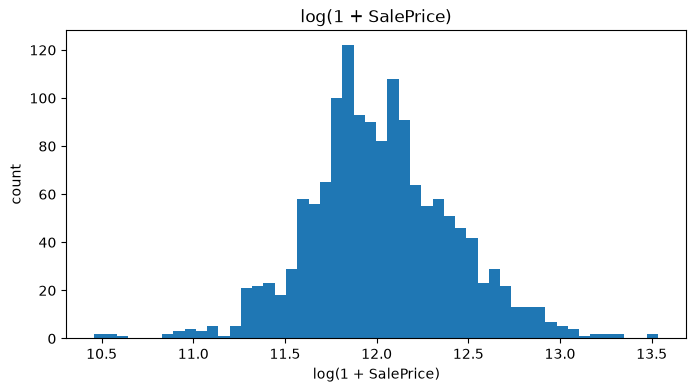

In [21]:
# distribution of a numeric column
plot_hist(df_data, col='SalePrice', log=True, bins=50) # log transform is necessary

For psf: both the raw psf and the log psf are skewed (different directions, the log-transform has more skew)

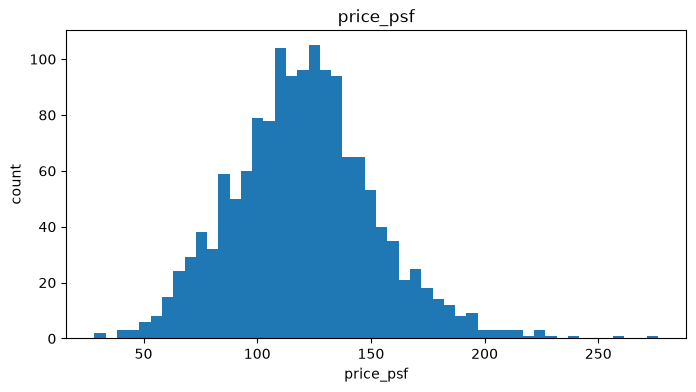

In [22]:
# distribution of psf
plot_hist(df_data, col='price_psf', log=False, bins=50) # log transform is necessary

Distribution of price per sq ft by neighbourhood

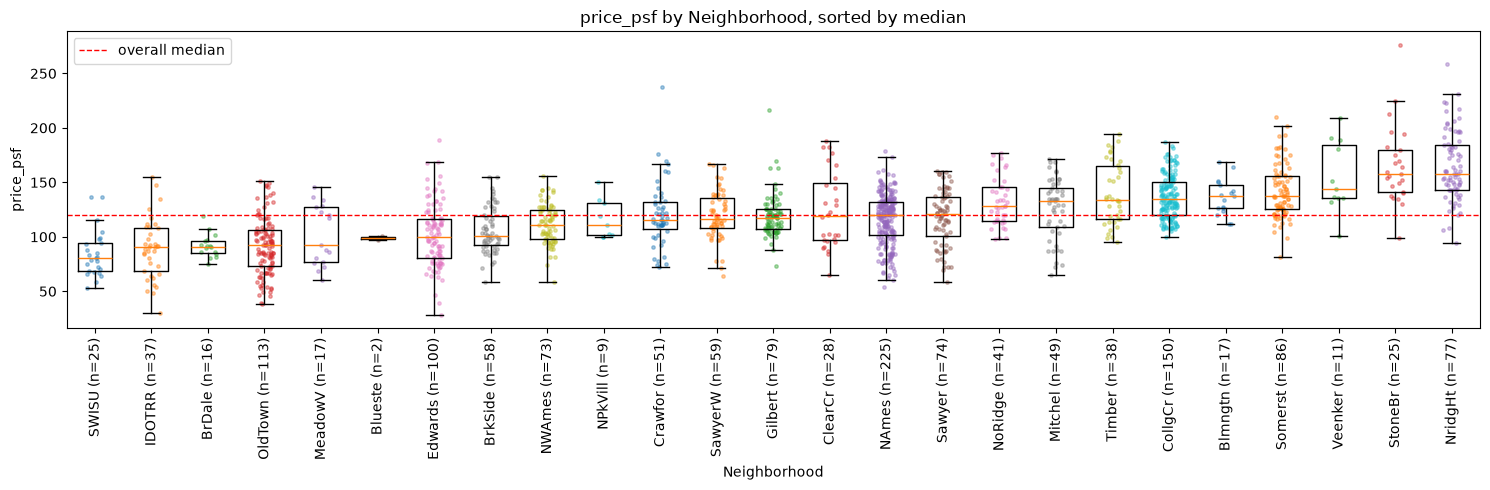

In [23]:
# price per sq ft by neighbourhood: boxplots with every house overlaid
plot_box_strip(df_data, col='price_psf', by='Neighborhood')

Are price-per-sq-ft differences across neighbourhoods meaningful? group means with 95% CIs + joint F-test.

TLDR: yes

Neighborhood (no controls): F = 44.3 on 24 dummies, p = 9e-154, R² = 0.388
Neighborhood (controlling for ['OverallQual', 'OverallCond', 'YearBuilt', 'GrLivArea']): F = 25.4 on 24 dummies, p = 6.5e-93, R² = 0.647


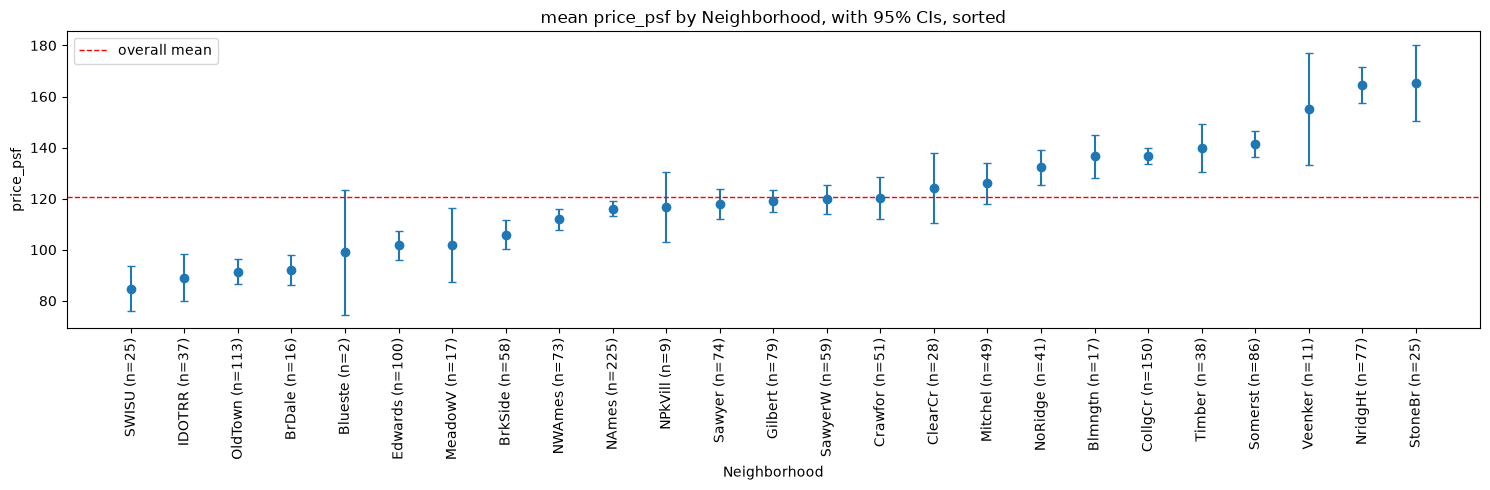

,n,mean,std,se,ci_half
g,,,,,
SWISU,25,84.755,21.559,4.312,8.899
IDOTRR,37,89.136,27.467,4.515,9.158
OldTown,113,91.427,25.983,2.444,4.843
BrDale,16,91.951,10.906,2.726,5.811
Blueste,2,98.969,2.723,1.926,24.468
Edwards,100,101.833,28.563,2.856,5.668
MeadowV,17,101.926,27.987,6.788,14.389
BrkSide,58,105.967,20.957,2.752,5.510
NWAmes,73,111.848,18.391,2.153,4.291


In [24]:
# are price-per-sq-ft differences across neighbourhoods meaningful? group means with 95% CIs + joint F-test
ui_controls = ['OverallQual', 'OverallCond', 'YearBuilt', 'GrLivArea']  # F-test repeated holding these fixed; [] for the raw test only

plot_group_means(df_data, col='price_psf', by='Neighborhood', log=False, l_controls=ui_controls)

Same thing for zoning

MSZoning (no controls): F = 64.2 on 4 dummies, p = 5e-50, R² = 0.111
MSZoning (controlling for ['OverallQual', 'OverallCond', 'YearBuilt', 'GrLivArea']): F = 15.9 on 4 dummies, p = 9.3e-13, R² = 0.572


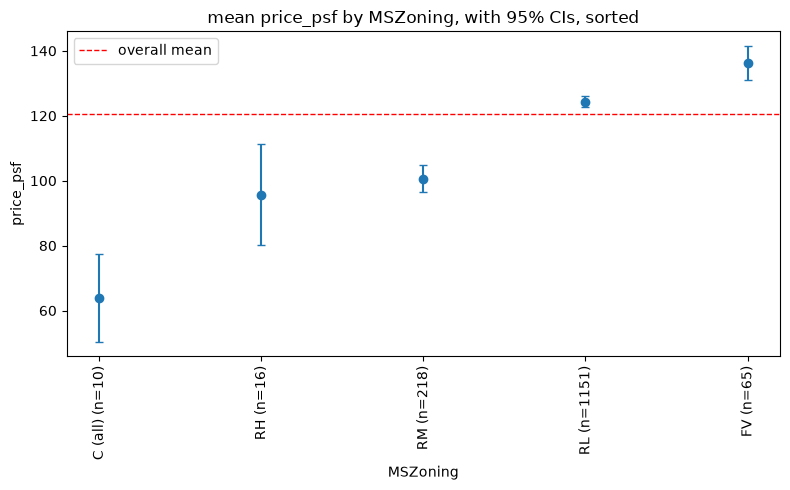

,n,mean,std,se,ci_half
g,,,,,
C (all),10,63.952,18.896,5.975,13.518
RH,16,95.735,29.420,7.355,15.677
RM,218,100.667,30.955,2.097,4.132
RL,1151,124.293,29.860,0.880,1.727
FV,65,136.280,20.891,2.591,5.177


In [25]:
ui_controls = ['OverallQual', 'OverallCond', 'YearBuilt', 'GrLivArea']  # F-test repeated holding these fixed; [] for the raw test only

plot_group_means(df_data, col='price_psf', by='MSZoning', log=False, l_controls=ui_controls)

## Naive model

Start with a forward selection methodology to pick a number of numeric regressors that covers most of the variability. 

I've decided to start with 6 regressors - arbitrarily. 

Note that we're using 100% of the dataset here - this is not ML yet. 

In [26]:
# correlation of each numeric feature with the target, top n by absolute value
ui_target = 'SalePrice' # any numeric column of df_data

df_corr = (
    df_data.select_dtypes('number')
    .drop(columns=['Id', 'MSSubClass'])  # MSSubClass is a dwelling-type code, not a quantity
    .corr()[ui_target]
    .drop(ui_target)
    .to_frame('corr')
)
df_corr['abs_corr'] = df_corr['corr'].abs()
df_corr.sort_values('abs_corr', ascending=False).head(15)

,corr,abs_corr
OverallQual,0.790982,0.790982
GrLivArea,0.708624,0.708624
GarageCars,0.640409,0.640409
GarageArea,0.623431,0.623431
TotalBsmtSF,0.613581,0.613581
1stFlrSF,0.605852,0.605852
price_psf,0.575505,0.575505
FullBath,0.560664,0.560664
TotRmsAbvGrd,0.533723,0.533723
YearBuilt,0.522897,0.522897


In [27]:
# forward selection: pick regressors one at a time by partial correlation with log SalePrice, given those already chosen
# collinearity filter: skip candidates whose VIF against the chosen set is above ui_max_vif
ui_n_features = 6 # total number of features to select
ui_max_vif = 5
l_exclude = ['Id', 'SalePrice', 'price_psf', 'MSSubClass'] # never candidates (price_psf is built from the target; MSSubClass is a code, not a quantity)

l_chosen = []
l_candidates = [c for c in df_data.select_dtypes('number').columns if c not in l_exclude]
df_fs = df_data[l_candidates].assign(log_SalePrice=np.log(df_data['SalePrice'])).dropna() # complete rows only (drops 339, mostly LotFrontage NaNs)

def residualise(sl, l_regs):
    """Residuals of sl after an OLS on l_regs (plus a constant); with no regressors, just demeaned."""
    if not l_regs:
        return sl - sl.mean()
    X = sm.add_constant(df_fs[l_regs])
    return sm.OLS(sl, X).fit().resid

while len(l_chosen) < ui_n_features:
    e_y = residualise(df_fs['log_SalePrice'], l_chosen)
    df_round = pd.DataFrame(index=l_candidates, columns=['pcorr', 'vif'], dtype=float)
    for c in l_candidates:
        x_res = residualise(df_fs[c], l_chosen)
        df_round.loc[c, 'pcorr'] = x_res.corr(e_y)
        df_round.loc[c, 'vif'] = df_fs[c].var() / x_res.var() # = 1 / (1 - R^2 of c on the chosen set)

    best = df_round[df_round['vif'] <= ui_max_vif]['pcorr'].abs().idxmax()
    l_skipped = df_round.index[df_round['pcorr'].abs() > abs(df_round.loc[best, 'pcorr'])].tolist() # ranked higher but too collinear
    print(f"add {best}: partial corr {df_round.loc[best, 'pcorr']:.3f}, VIF {df_round.loc[best, 'vif']:.2f}, skipped for collinearity: {l_skipped}")
    l_chosen.append(best)
    l_candidates.remove(best)

add OverallQual: partial corr 0.828, VIF 1.00, skipped for collinearity: []
add GrLivArea: partial corr 0.433, VIF 1.58, skipped for collinearity: []
add YearBuilt: partial corr 0.385, VIF 1.62, skipped for collinearity: []
add OverallCond: partial corr 0.313, VIF 1.26, skipped for collinearity: []


add GarageCars: partial corr 0.267, VIF 1.85, skipped for collinearity: []
add BsmtFullBath: partial corr 0.261, VIF 1.04, skipped for collinearity: []


In [28]:
# OLS: log SalePrice on the forward-selected features
df_ols = df_data[l_chosen].assign(log_SalePrice=np.log(df_data['SalePrice'])).dropna() # complete rows for the chosen features only
X = sm.add_constant(df_ols[l_chosen])
y = df_ols['log_SalePrice']

model_naive = sm.OLS(y, X).fit(cov_type='HC1')  # robust standard errors with Heteroscedasticity-Consistent covariance matrix estimators
model_naive.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:          log_SalePrice   R-squared:                       0.836
Model:                            OLS   Adj. R-squared:                  0.835
Method:                 Least Squares   F-statistic:                     714.7
Date:                Tue, 27 Oct 2026   Prob (F-statistic):               0.00
Time:                        22:55:04   Log-Likelihood:                 588.54
No. Observations:                1460   AIC:                            -1163.
Df Residuals:                    1453   BIC:                            -1126.
Df Model:                           6                                         
Covariance Type:                  HC1                                         
================================================================================
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            3.7063      0.479      7.732      0.000       2.767       4.646
OverallQual      0.0996      0.005     18.559      0.000       0.089       0.110
GrLivArea        0.0003   3.19e-05      8.854      0.000       0.000       0.000
YearBuilt        0.0034      0.000     14.446      0.000       0.003       0.004
OverallCond      0.0578      0.005     12.713      0.000       0.049       0.067
GarageCars       0.0930      0.012      7.715      0.000       0.069       0.117
BsmtFullBath     0.0941      0.011      8.481      0.000       0.072       0.116
==============================================================================
Omnibus:                      756.586   Durbin-Watson:                   1.988
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            18841.535
Skew:                          -1.881   Prob(JB):                         0.00
Kurtosis:                      20.192   Cond. No.                     2.35e+05
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC1)
[2] The condition number is large, 2.35e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

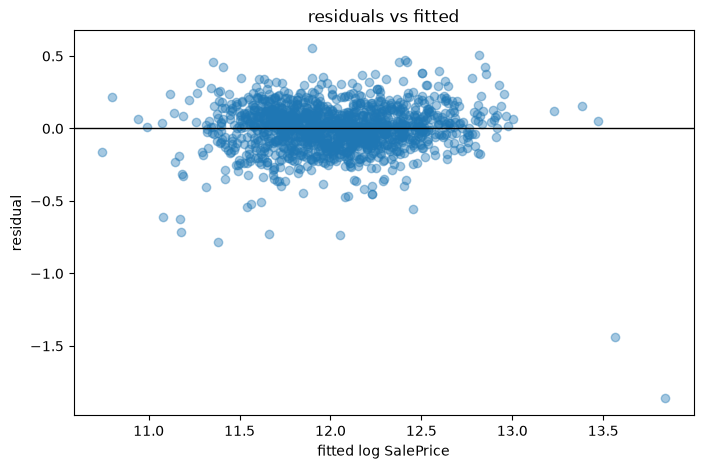

In [29]:
# residuals vs fitted values: a fan shape (spread growing with fitted price) = heteroskedasticity
ui_model = model_naive

## plotting charts below
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(ui_model.fittedvalues, ui_model.resid, alpha=0.4)
ax.axhline(0, color='black', linewidth=1)
ax.set_title('residuals vs fitted')
ax.set_xlabel('fitted log SalePrice')
ax.set_ylabel('residual')
plt.show()

## Naive+ model

Same idea as the naive model (forward selection → OLS), but predicting **price per sq ft** (predicted price = predicted psf × `GrLivArea`), on the cleaned, outlier-dropped, one-hot-encoded features, with **10** features, and validated by **5-fold CV**: each fold runs the *whole* procedure (preprocess → forward selection → OLS) on its 80% and is scored on its 20% with the Kaggle metric (RMSE on log price). Dummies held by fewer than 10 training houses aren't candidates (a 1-house dummy can fit that house exactly).

Final model, two ways: **(a)** average the 5 folds' coefficients (a feature a fold didn't pick counts as 0), **(b)** rerun the procedure on 100% of the training data.

Target choice (CV RMSE on log price): raw psf 0.161, log psf (`ui_log_psf = True`) 0.152, log price (first version of naive+) 0.154.

Is (a) better than (b)? Checked on 20 random 80/20 splits, with the log-price target (both built on the 80%, scored on the untouched 20%): (a) RMSE 0.160 vs (b) 0.163, (a) better in 17 of 20. Small but consistent. Why: forward selection is *unstable* (small data changes swap features in and out, see the fold table), and averaging models that made different picks smooths that out. That's the idea behind bagging (ensemble methods, week 7). For OLS on a *fixed* feature set, averaging fold fits wouldn't help, since each fit sees only 80% of the data.

The CV score's main job is honesty: it's an estimate of out-of-sample error for the whole procedure, selection included, which the naive model never had.

In [30]:
# naive+ : forward selection + OLS predicting price per sq ft, on the cleaned, encoded features, validated with 5-fold CV
ui_n_features = 10
ui_max_vif = 5
ui_min_support = 10  # a dummy must be 1 for at least this many training houses to be a candidate (a 1-house dummy can fit that house exactly)
ui_n_folds = 5

ui_log_psf = False  # False: target = price per sq ft; True: target = log(price per sq ft)

def target_plus(sl_price, df_X):
    """naive+'s target from sale prices: price per sq ft, or its log if ui_log_psf."""
    sl_psf = sl_price / df_X['GrLivArea']
    return np.log(sl_psf) if ui_log_psf else sl_psf

def to_price(y_hat, df_X):
    """Model output (psf or log psf) -> sale price, using each house's GrLivArea."""
    psf_hat = np.exp(y_hat) if ui_log_psf else np.clip(y_hat, 1, None)  # clip: guard against a (very unlikely) negative psf
    return psf_hat * df_X['GrLivArea']

def rmse_log_price(price_hat, price_true):
    """The Kaggle metric: RMSE between log predicted and log true prices."""
    return np.sqrt(np.mean((np.log(price_hat) - np.log(price_true)) ** 2))

def residualise_all(M, Z):
    """Residuals of every column of M after OLS on Z (Z includes the constant)."""
    beta = np.linalg.lstsq(Z, M, rcond=None)[0]
    return M - Z @ beta

def forward_select(df_X, sl_y, n_features=ui_n_features, max_vif=ui_max_vif, min_support=ui_min_support):
    """Forward selection by partial correlation with sl_y, skipping candidates with VIF > max_vif against the chosen set."""
    l_cand = [c for c in df_X.columns if df_X[c].nunique() > 2 or df_X[c].sum() >= min_support]
    M, y = df_X[l_cand].to_numpy(float), sl_y.to_numpy(float)
    l_chosen = []
    while len(l_chosen) < n_features:
        Z = np.column_stack([np.ones(len(y))] + [df_X[c].to_numpy(float) for c in l_chosen])
        e_y = residualise_all(y[:, None], Z)[:, 0]
        M_res = residualise_all(M, Z)
        var_res = M_res.var(axis=0)
        with np.errstate(divide='ignore', invalid='ignore'):
            vif = M.var(axis=0) / var_res
            pcorr = (M_res * e_y[:, None]).mean(axis=0) / np.sqrt(var_res * e_y.var())
        pcorr[(vif > max_vif) | ~np.isfinite(pcorr) | np.isin(l_cand, l_chosen)] = 0
        l_chosen.append(l_cand[int(np.argmax(np.abs(pcorr)))])
    return l_chosen

## 5-fold CV: each fold runs the WHOLE procedure (drop outliers -> preprocess -> forward selection -> OLS) on its 80%, scores on all of its 20%
kfold = KFold(n_splits=ui_n_folds, shuffle=True, random_state=0)
l_fold_rmse, l_fold_coefs = [], []
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='Found unknown categories')  # rare levels missing from a fold's 80%: encoded as baseline
    for k, (idx_tr, idx_va) in enumerate(kfold.split(df_X_train)):
        df_X_tr, sl_price_tr = drop_outliers(df_X_train.iloc[idx_tr], df_train['SalePrice'].iloc[idx_tr])  # from the fold's 80% only
        pre = clone(preprocess)
        df_tr = pre.fit_transform(df_X_tr)
        df_va = pre.transform(df_X_train.iloc[idx_va])
        y_tr = target_plus(sl_price_tr, df_X_tr)
        l_sel = forward_select(df_tr, y_tr)
        res = sm.OLS(y_tr, sm.add_constant(df_tr[l_sel])).fit()
        y_hat = res.predict(sm.add_constant(df_va[l_sel], has_constant='add'))
        l_fold_rmse.append(rmse_log_price(to_price(y_hat, df_X_train.iloc[idx_va]), df_train['SalePrice'].iloc[idx_va]))  # scored like Kaggle
        l_fold_coefs.append(res.params.rename(f'fold {k + 1}'))

print('validation RMSE on log price (the Kaggle metric) per fold:', np.round(l_fold_rmse, 4))
print(f'mean {np.mean(l_fold_rmse):.4f}, sd {np.std(l_fold_rmse):.4f}')

## which features each fold picked (coefficient where picked, blank where not)
df_fold_coefs = pd.concat(l_fold_coefs, axis=1)
df_fold_coefs.insert(0, 'n_folds', df_fold_coefs.drop(index='const').notna().sum(axis=1))
df_fold_coefs.sort_values('n_folds', ascending=False)

validation RMSE on log price (the Kaggle metric) per fold: [0.1865 0.1491 0.1805 0.1598 0.1498]
mean 0.1651, sd 0.0156


,n_folds,fold 1,fold 2,fold 3,fold 4,fold 5
YearBuilt,5.0,0.317633,0.318215,0.339046,0.324048,0.355291
has_2ndflr,5.0,-17.139438,-18.907090,-16.444126,-19.918485,-17.059357
OverallQual_sq,5.0,0.703961,0.726313,0.634570,0.565030,0.700929
OverallCond,5.0,5.818137,6.104554,6.416805,5.404145,6.772922
log_LotArea,5.0,9.468428,8.211004,8.072101,6.779275,10.026112
SaleType_New,4.0,15.736568,23.507703,NaN,15.090095,12.391623
TotRmsAbvGrd,4.0,-3.588018,-5.158470,-5.881949,NaN,-4.071478
Functional_Typ,4.0,11.606795,14.334207,10.925762,13.370419,NaN
BedroomAbvGr,3.0,-5.271395,NaN,NaN,-8.141252,-4.101291
BsmtFullBath,3.0,NaN,8.558517,8.995513,NaN,8.573414


In [31]:
# naive+ final model, two ways: (a) average the 5 folds' coefficients; (b) refit the whole procedure on 100% of the training data
## (a) averaged weights: a feature a fold didn't pick counts as 0 in that fold
df_coefs = df_fold_coefs.drop(columns='n_folds')
sl_coef_avg = df_coefs.fillna(0).mean(axis=1)

## (b) refit on 100%: drop outliers -> preprocess -> forward selection -> OLS, all on the 1,460 training houses
df_X_fit, sl_price_fit = drop_outliers(df_X_train, df_train['SalePrice'])
sl_y_fit = target_plus(sl_price_fit, df_X_fit)
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='Found unknown categories')
    pre_full = clone(preprocess)
    df_X_train_enc = pre_full.fit_transform(df_X_fit)
    df_X_test_enc = pre_full.transform(df_X_test)
l_chosen_plus = forward_select(df_X_train_enc, sl_y_fit)
model_plus = sm.OLS(sl_y_fit, sm.add_constant(df_X_train_enc[l_chosen_plus])).fit(cov_type='HC1')

## test-set predictions from both (psf -> price = psf x GrLivArea)
X_test_all = sm.add_constant(df_X_test_enc, has_constant='add')
sl_pred_avg = to_price(X_test_all[sl_coef_avg.index] @ sl_coef_avg, df_X_test)
sl_pred_refit = to_price(model_plus.predict(X_test_all[['const'] + l_chosen_plus]), df_X_test)
print(f'(a) uses {len(sl_coef_avg) - 1} features, (b) uses {len(l_chosen_plus)}; '
      f'the two test predictions differ by {np.mean(np.abs(np.log(sl_pred_avg / sl_pred_refit))):.1%} on average (in log terms)')
model_plus.summary()

(a) uses 16 features, (b) uses 10; the two test predictions differ by 2.1% on average (in log terms)


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.735
Model:                            OLS   Adj. R-squared:                  0.733
Method:                 Least Squares   F-statistic:                     330.5
Date:                Tue, 27 Oct 2026   Prob (F-statistic):               0.00
Time:                        22:55:05   Log-Likelihood:                -5996.8
No. Observations:                1440   AIC:                         1.202e+04
Df Residuals:                    1429   BIC:                         1.207e+04
Df Model:                          10                                         
Covariance Type:                  HC1                                         
====================================================================================
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const             -635.6445     41.295    -15.393      0.000    -716.581    -554.708
YearBuilt            0.3245      0.020     16.312      0.000       0.286       0.364
has_2ndflr         -17.0794      0.983    -17.376      0.000     -19.006     -15.153
OverallQual_sq       0.6893      0.036     18.963      0.000       0.618       0.760
OverallCond          5.8001      0.455     12.741      0.000       4.908       6.692
BedroomAbvGr        -5.2683      0.897     -5.875      0.000      -7.026      -3.511
log1p_BsmtFinSF1     1.5922      0.147     10.843      0.000       1.304       1.880
log_LotArea          9.2073      0.876     10.515      0.000       7.491      10.923
Functional_Typ      11.9905      1.775      6.753      0.000       8.511      15.470
SaleType_New        14.6966      1.906      7.711      0.000      10.961      18.432
TotRmsAbvGrd        -3.6035      0.508     -7.089      0.000      -4.600      -2.607
==============================================================================
Omnibus:                       62.552   Durbin-Watson:                   1.985
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              178.373
Skew:                          -0.133   Prob(JB):                     1.85e-39
Kurtosis:                       4.704   Cond. No.                     1.87e+05
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC1)
[2] The condition number is large, 1.87e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

## Naive++ model

Same procedure as naive+ (forward selection of 10 features → OLS, on the cleaned, outlier-dropped, encoded data), with two changes:
* **Target = log price per sq ft.** Predicted price = exp(predicted log psf) × `GrLivArea`. Since log price = log psf + log area, the fit's squared error is exactly the Kaggle metric's log-price error.
* **Final model = (b):** the whole procedure refit on 100% of the training data. The 5-fold CV RMSE below estimates exactly this procedure, so the CV number and the submitted model match (unlike naive+'s averaged weights).

In [32]:
# naive++ : forward selection + OLS predicting LOG price per sq ft, scored on the same 5 folds as naive+ (kfold, random_state=0)
## every model goes through cv_rmse, so they are all compared on the same folds with the Kaggle metric on sale price
d_cv = {f"naive+ ({'log psf' if ui_log_psf else 'psf'}, fs10, OLS)": l_fold_rmse}  # model name -> its 5 fold RMSEs; naive+'s come from its own loop (same kfold)

def cv_rmse(name, fit_predict):
    """5-fold CV RMSE on log price. fit_predict(df_X_tr, sl_price_tr, df_X_va) -> predicted SalePrice for df_X_va.
    Each model builds its own target from sl_price_tr, so psf, log psf and log price models stay comparable.
    Every fit_predict must start with drop_outliers on its training rows; the validation rows are all scored."""
    l_rmse = []
    with warnings.catch_warnings():
        warnings.filterwarnings('ignore', message='Found unknown categories')
        for idx_tr, idx_va in kfold.split(df_X_train):
            price_hat = fit_predict(df_X_train.iloc[idx_tr], df_train['SalePrice'].iloc[idx_tr], df_X_train.iloc[idx_va])
            l_rmse.append(rmse_log_price(price_hat, df_train['SalePrice'].iloc[idx_va]))
    d_cv[name] = l_rmse
    df_cv = pd.DataFrame(d_cv, index=[f'fold {k + 1}' for k in range(kfold.get_n_splits())]).T
    return df_cv.assign(mean=df_cv.mean(axis=1), sd=df_cv.std(axis=1, ddof=0)).round(4)

def fit_naive_pp(df_X_tr, sl_price_tr):
    """The whole naive++ procedure on one training set: drop outliers -> preprocess -> forward selection on log psf -> OLS."""
    df_X_tr, sl_price_tr = drop_outliers(df_X_tr, sl_price_tr)
    pre = clone(preprocess)
    df_tr = pre.fit_transform(df_X_tr)
    y_tr = np.log(sl_price_tr / df_X_tr['GrLivArea'])
    l_sel = forward_select(df_tr, y_tr)
    return pre, l_sel, sm.OLS(y_tr, sm.add_constant(df_tr[l_sel])).fit()

def predict_naive_pp(fitted, df_X):
    """Predicted sale price = exp(predicted log psf) x GrLivArea."""
    pre, l_sel, res = fitted
    y_hat = res.predict(sm.add_constant(pre.transform(df_X)[l_sel], has_constant='add'))
    return np.exp(y_hat) * df_X['GrLivArea']

cv_rmse('naive++ (log psf, fs10, OLS)', lambda df_X_tr, sl_price_tr, df_X_va: predict_naive_pp(fit_naive_pp(df_X_tr, sl_price_tr), df_X_va))

,fold 1,fold 2,fold 3,fold 4,fold 5,mean,sd
"naive+ (psf, fs10, OLS)",0.1865,0.1491,0.1805,0.1598,0.1498,0.1651,0.0156
"naive++ (log psf, fs10, OLS)",0.1821,0.1336,0.1790,0.1275,0.1395,0.1523,0.0234


In [33]:
# naive++ final model = (b): the whole procedure (outlier drop included) refit on all 1,460 training houses (what the CV RMSE above estimates)
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='Found unknown categories')
    fitted_pp = fit_naive_pp(df_X_train, df_train['SalePrice'])
    sl_pred_pp = predict_naive_pp(fitted_pp, df_X_test)  # test-set sale prices
print('features:', fitted_pp[1])
fitted_pp[2].summary()

features: ['YearBuilt', 'has_2ndflr', 'OverallCond', 'OverallQual_sq', 'TotRmsAbvGrd', 'log_LotArea', 'log1p_BsmtFinSF1', 'Functional_Typ', 'SaleType_New', 'KitchenAbvGr']


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.739
Model:                            OLS   Adj. R-squared:                  0.737
Method:                 Least Squares   F-statistic:                     405.1
Date:                Tue, 27 Oct 2026   Prob (F-statistic):               0.00
Time:                        22:55:05   Log-Likelihood:                 822.98
No. Observations:                1440   AIC:                            -1624.
Df Residuals:                    1429   BIC:                            -1566.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const               -2.9880      0.347     -8.599      0.000      -3.670      -2.306
YearBuilt            0.0035      0.000     20.652      0.000       0.003       0.004
has_2ndflr          -0.1510      0.009    -16.757      0.000      -0.169      -0.133
OverallCond          0.0601      0.004     16.433      0.000       0.053       0.067
OverallQual_sq       0.0052      0.000     17.377      0.000       0.005       0.006
TotRmsAbvGrd        -0.0432      0.003    -12.915      0.000      -0.050      -0.037
log_LotArea          0.0745      0.008      9.433      0.000       0.059       0.090
log1p_BsmtFinSF1     0.0128      0.001      9.948      0.000       0.010       0.015
Functional_Typ       0.1223      0.015      8.231      0.000       0.093       0.151
SaleType_New         0.1028      0.015      7.018      0.000       0.074       0.132
KitchenAbvGr        -0.1270      0.018     -6.874      0.000      -0.163      -0.091
==============================================================================
Omnibus:                      285.046   Durbin-Watson:                   1.973
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1252.343
Skew:                          -0.874   Prob(JB):                    1.14e-272
Kurtosis:                       7.221   Cond. No.                     1.90e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.9e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

## Lasso and Ridge models

Same target as naive++ (log price per sq ft), but on the **full** engineered feature set from `make_preprocess_reg` (no one-hot baseline; numeric columns standardised; dummies and `has_*` flags left 0/1; about 270 columns), with the outliers dropped from each fit's training rows. Nothing is selected beforehand: the penalty does the shrinking (and, for Lasso, the selecting).

**Tuning α in two levels**, on the same 5 folds as every other model. Level 1 uses 20 log-equal steps over a broad range. Level 2 uses 20 log-equal steps between the two level-1 neighbours of the level-1 best. sklearn scales the two losses differently (Lasso: (1/2n)·RSS + α·Σ|w|; Ridge: RSS + α·Σw²), so their α values can't be compared with each other.

**Two CV numbers per model:**
* the **tuning curve's minimum**: the CV RMSE at the chosen α. It's slightly optimistic, being the best of 40 tries on the same folds (reading 01 §5.3);
* the **nested CV RMSE** (`cv_rmse`): the whole two-level search rerun inside each outer fold's 80% and scored on its 20%. This is the honest number, the one to log and to compare with naive++.

In [34]:
# Lasso / Ridge helpers: preprocess each fold once and reuse it for every alpha; two-level alpha search; nested-CV fit_predict
from sklearn.linear_model import Lasso, Ridge

ui_n_alphas = 20  # log-equal steps per level
d_alpha_coarse = {'Lasso': np.logspace(-5, 0, ui_n_alphas), 'Ridge': np.logspace(-2, 5, ui_n_alphas)}  # level 1: broad ranges
d_model_cls = {'Lasso': Lasso, 'Ridge': Ridge}

def prepare_folds(df_X, sl_price, folds):
    """Per fold, done once and reused for every alpha: drop outliers from the training rows, fit the preprocessing on them, transform both sides."""
    l_folds = []
    with warnings.catch_warnings():
        warnings.filterwarnings('ignore', message='Found unknown categories')
        for idx_tr, idx_va in folds:
            df_X_tr, sl_price_tr = drop_outliers(df_X.iloc[idx_tr], sl_price.iloc[idx_tr])
            pre = make_preprocess_reg()
            l_folds.append({
                'X_tr': pre.fit_transform(df_X_tr), 'y_tr': np.log(sl_price_tr / df_X_tr['GrLivArea']),  # target: log psf
                'X_va': pre.transform(df_X.iloc[idx_va]), 'area_va': df_X.iloc[idx_va]['GrLivArea'], 'price_va': sl_price.iloc[idx_va],
            })
    return l_folds

def cv_curve(name, alphas, l_folds):
    """CV RMSE on log price (the Kaggle metric) for each alpha: one row per alpha, one column per fold."""
    df = pd.DataFrame(index=pd.Index(alphas, name='alpha'), columns=[f'fold {k + 1}' for k in range(len(l_folds))], dtype=float)
    for a in alphas:
        for k, f in enumerate(l_folds):
            m = d_model_cls[name](alpha=a, max_iter=50_000).fit(f['X_tr'], f['y_tr'])
            df.loc[a, f'fold {k + 1}'] = rmse_log_price(np.exp(m.predict(f['X_va'])) * f['area_va'], f['price_va'])
    return df

def two_level_search(name, l_folds, n=ui_n_alphas):
    """Level 1: the broad grid. Level 2: n log-equal steps between the level-1 best's two neighbours. Returns (curve 1, curve 2, best alpha)."""
    coarse = d_alpha_coarse[name]
    df_c1 = cv_curve(name, coarse, l_folds)
    k = int(np.argmin(df_c1.mean(axis=1)))
    if k in (0, len(coarse) - 1):
        print(f'{name}: the level-1 best alpha {coarse[k]:.2e} is at the edge of the grid, so the grid should be extended')
    df_c2 = cv_curve(name, np.geomspace(coarse[max(k - 1, 0)], coarse[min(k + 1, len(coarse) - 1)], n), l_folds)
    return df_c1, df_c2, df_c2.mean(axis=1).idxmin()

def refit_penalised(name, alpha, df_X_tr, sl_price_tr, **kw):
    """One model at a given alpha (plus any other model settings in kw, e.g. l1_ratio), fitted on a training set with its outliers dropped."""
    df_X_fit, sl_price_fit = drop_outliers(df_X_tr, sl_price_tr)
    model = Pipeline([('pre', make_preprocess_reg()), ('reg', d_model_cls[name](alpha=alpha, max_iter=50_000, **kw))])
    with warnings.catch_warnings():
        warnings.filterwarnings('ignore', message='Found unknown categories')
        return model.fit(df_X_fit, np.log(sl_price_fit / df_X_fit['GrLivArea']))

def predict_penalised(model, df_X):
    """Predicted sale price = exp(predicted log psf) x GrLivArea."""
    with warnings.catch_warnings():
        warnings.filterwarnings('ignore', message='Found unknown categories')
        return np.exp(model.predict(df_X)) * df_X['GrLivArea']

def fit_predict_penalised(name):
    """For cv_rmse (nested CV): on each outer fold's 80%, run the two-level search on 5 inner folds, refit at the best alpha, predict the 20%."""
    def fit_predict(df_X_tr, sl_price_tr, df_X_va):
        inner = KFold(n_splits=ui_n_folds, shuffle=True, random_state=0).split(df_X_tr)
        _, _, alpha = two_level_search(name, prepare_folds(df_X_tr, sl_price_tr, inner))
        print(f'  {name}: inner search picked alpha {alpha:.3g}')
        return predict_penalised(refit_penalised(name, alpha, df_X_tr, sl_price_tr), df_X_va)
    return fit_predict

Lasso: best alpha 0.000474, CV RMSE there 0.1395 (the tuning-curve minimum: slightly optimistic)
Ridge: best alpha 7.75, CV RMSE there 0.1402 (the tuning-curve minimum: slightly optimistic)


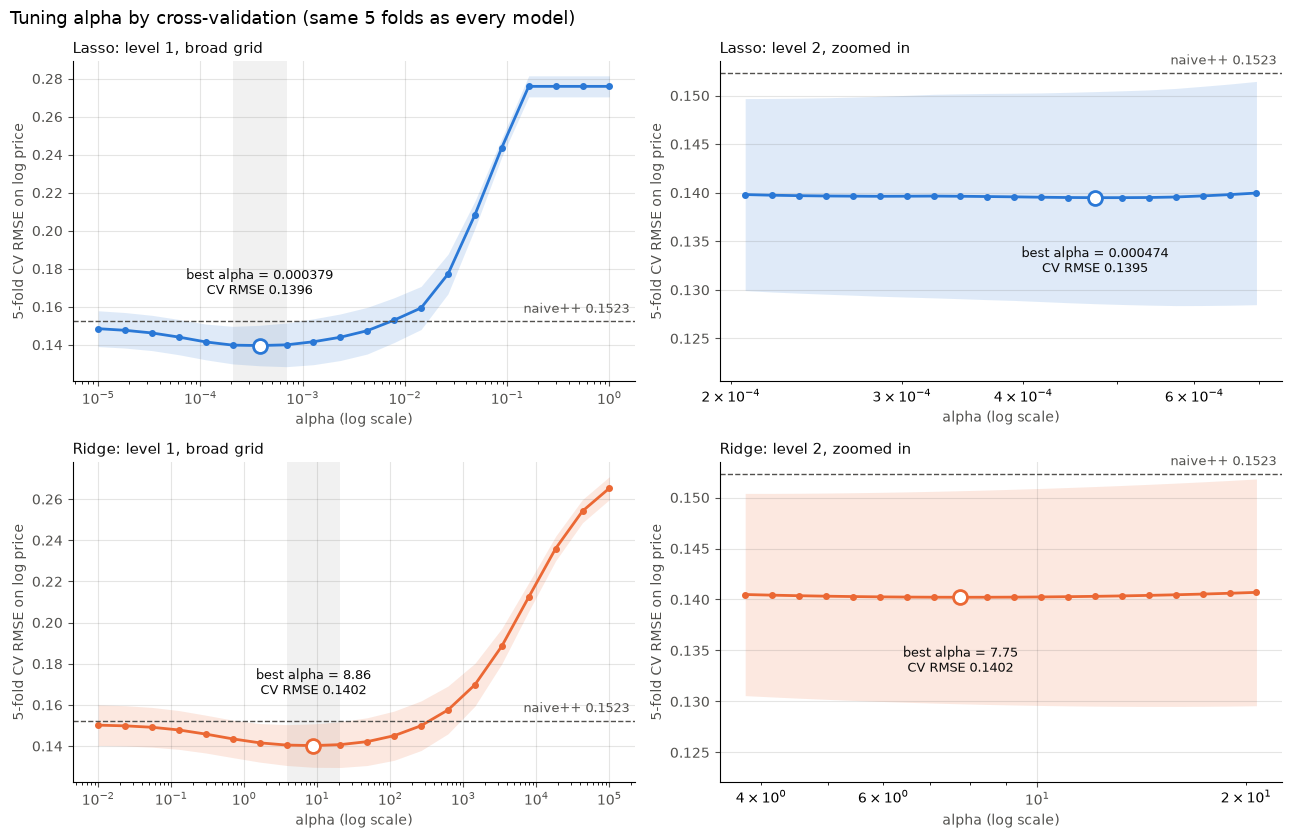

In [35]:
# tune alpha on all 1,460 training houses (the same 5 folds as every model), two levels per model
l_folds_all = prepare_folds(df_X_train, df_train['SalePrice'], kfold.split(df_X_train))
d_search = {name: two_level_search(name, l_folds_all) for name in ['Lasso', 'Ridge']}  # name -> (curve 1, curve 2, best alpha)
for name, (df_c1, df_c2, alpha) in d_search.items():
    print(f'{name}: best alpha {alpha:.3g}, CV RMSE there {df_c2.mean(axis=1).min():.4f} (the tuning-curve minimum: slightly optimistic)')

## chart: CV RMSE against alpha. Left: level 1 (broad grid; shaded = the range level 2 zooms into). Right: level 2.
## Band = ± 1 standard error of the 5-fold mean. Dashed line = naive++ on the same folds, for reference
cv_naive_pp = np.mean(d_cv['naive++ (log psf, fs10, OLS)'])
d_color = {'Lasso': '#2a78d6', 'Ridge': '#eb6834'}
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
for r, (name, (df_c1, df_c2, alpha)) in enumerate(d_search.items()):
    for c, (df_c, level) in enumerate([(df_c1, 'level 1, broad grid'), (df_c2, 'level 2, zoomed in')]):
        ax = axes[r, c]
        sl_mean = df_c.mean(axis=1)
        sl_se = df_c.std(axis=1, ddof=1) / np.sqrt(df_c.shape[1])
        if c == 0:
            ax.axvspan(df_c2.index.min(), df_c2.index.max(), color='#52514e', alpha=0.08, linewidth=0)
        ax.fill_between(sl_mean.index, sl_mean - sl_se, sl_mean + sl_se, color=d_color[name], alpha=0.15, linewidth=0)
        ax.plot(sl_mean.index, sl_mean, '-o', color=d_color[name], linewidth=2, markersize=4)
        ax.axhline(cv_naive_pp, color='#52514e', linestyle='--', linewidth=1)
        ax.annotate(f'naive++ {cv_naive_pp:.4f}', (1, cv_naive_pp), xycoords=('axes fraction', 'data'),
                    xytext=(-4, 4), textcoords='offset points', ha='right', va='bottom', color='#52514e', fontsize=9)
        best = sl_mean.idxmin()
        ax.plot(best, sl_mean[best], 'o', color=d_color[name], markersize=10, markerfacecolor='white', markeredgewidth=2, zorder=3)
        ax.annotate(f'best alpha = {best:.3g}\nCV RMSE {sl_mean[best]:.4f}', (best, sl_mean[best]), xytext=(0, 34 if c == 0 else -34),
                    textcoords='offset points', ha='center', va='bottom' if c == 0 else 'top', color='#0b0b0b', fontsize=9)
        ax.set_xscale('log')
        ax.set_title(f'{name}: {level}', loc='left', fontsize=11, color='#0b0b0b')
        ax.set_xlabel('alpha (log scale)', color='#52514e')
        ax.set_ylabel('5-fold CV RMSE on log price', color='#52514e')
        ax.grid(color='#52514e', alpha=0.15, linewidth=0.8)
        ax.spines[['top', 'right']].set_visible(False)
        ax.tick_params(colors='#52514e')
        if c == 1:  # leave room under the marker for its label
            lo, hi = ax.get_ylim()
            ax.set_ylim(lo - 0.25 * (hi - lo), hi)
fig.suptitle('Tuning alpha by cross-validation (same 5 folds as every model)', x=0.01, ha='left', fontsize=13)
plt.tight_layout()
plt.show()

In [36]:
# honest CV RMSE (nested CV): the whole two-level search is rerun inside each outer fold's 80% (on 5 inner folds of it),
# then the model is refit there at the alpha it picked and scored on the outer 20%. These are the numbers to log and compare
cv_rmse('Lasso (log psf, all features)', fit_predict_penalised('Lasso'))
cv_rmse('Ridge (log psf, all features)', fit_predict_penalised('Ridge'))

  Lasso: inner search picked alpha 0.000718


  Lasso: inner search picked alpha 0.000556


  Lasso: inner search picked alpha 0.000294


  Lasso: inner search picked alpha 0.000323


  Lasso: inner search picked alpha 0.000765


...

  Ridge: inner search picked alpha 10.1


  Ridge: inner search picked alpha 8.47


  Ridge: inner search picked alpha 4.74


  Ridge: inner search picked alpha 10.1


,fold 1,fold 2,fold 3,fold 4,fold 5,mean,sd
"naive+ (psf, fs10, OLS)",0.1865,0.1491,0.1805,0.1598,0.1498,0.1651,0.0156
"naive++ (log psf, fs10, OLS)",0.1821,0.1336,0.1790,0.1275,0.1395,0.1523,0.0234
"Lasso (log psf, all features)",0.1667,0.1221,0.1662,0.1238,0.1232,0.1404,0.0213
"Ridge (log psf, all features)",0.1649,0.1224,0.1691,0.1248,0.1237,0.1410,0.0213


In [37]:
# final models = (b): the alpha from the two-level search on all 1,460 houses (the chart above), refit on all of them (outliers dropped)
d_model_pen = {name: refit_penalised(name, alpha, df_X_train, df_train['SalePrice']) for name, (_, _, alpha) in d_search.items()}
d_pred_pen = {name: predict_penalised(model, df_X_test) for name, model in d_model_pen.items()}  # test-set sale prices

for name, model in d_model_pen.items():
    w = model[-1].coef_
    print(f"{name}: alpha {model[-1].alpha:.3g}, {np.sum(w != 0)} of {w.size} coefficients non-zero, L2 norm {np.linalg.norm(w):.3f}")

Lasso: alpha 0.000474, 104 of 268 coefficients non-zero, L2 norm 0.427


Ridge: alpha 7.75, 268 of 268 coefficients non-zero, L2 norm 0.445


## Elastic Net model

sklearn's `ElasticNet` minimises $\frac{1}{2n}\lVert y - Xw\rVert^2 + \lambda_1\lVert w\rVert_1 + \tfrac12\lambda_2\lVert w\rVert_2^2$, where $\lambda_1 = \alpha\cdot$`l1_ratio` and $\lambda_2 = \alpha\,(1 - $`l1_ratio`$)$. So pure Lasso is $\lambda_2 = 0$ and pure Ridge is $\lambda_1 = 0$.

Tuning: a random search over $(\lambda_1, \lambda_2)$, drawn uniformly on the log scale, in two levels like Lasso/Ridge: 1,000 pairs in a broad box, then 500 within one decade of the level-1 best. Scored with nested CV like every model.

In [38]:
# Elastic Net helpers: random search over (lambda_1, lambda_2), drawn log-uniformly, in two levels (broad box, then a zoomed box)
# sklearn's ElasticNet minimises (1/2n)·RSS + alpha·l1_ratio·|w|₁ + ½·alpha·(1 − l1_ratio)·|w|², so with
# lambda_1 = alpha·l1_ratio and lambda_2 = alpha·(1 − l1_ratio) the penalty is lambda_1·|w|₁ + ½·lambda_2·|w|²
from sklearn.linear_model import ElasticNet
from joblib import Parallel, delayed

d_model_cls['ElasticNet'] = ElasticNet
ui_en_n_draws = (1000, 500)  # random (lambda_1, lambda_2) pairs: level 1, level 2
ui_en_box = {'lambda_1': (1e-6, 1e-1), 'lambda_2': (1e-6, 1e1)}  # level 1: broad box; each axis's low end is ~pure Ridge (lambda_1) or ~pure Lasso (lambda_2)
ui_en_zoom = 1.0  # level 2: ± this many decades around the level-1 best, on each axis
ui_en_seed = 0

def en_params(l1, l2):
    """(lambda_1, lambda_2) -> sklearn's (alpha, l1_ratio)."""
    return {'alpha': l1 + l2, 'l1_ratio': l1 / (l1 + l2)}

def draw_log_uniform(rng, box, n):
    """n random points, uniform on the log scale within box = {axis: (low, high)}."""
    return pd.DataFrame({k: 10 ** rng.uniform(np.log10(lo), np.log10(hi), n) for k, (lo, hi) in box.items()})

def en_fold_rmses(l1, l2, l_folds):
    """One (lambda_1, lambda_2) pair: CV RMSE on log price in each fold."""
    l_rmse = []
    for f in l_folds:
        m = ElasticNet(**en_params(l1, l2), max_iter=50_000, precompute=True).fit(f['X_tr'], f['y_tr'])
        l_rmse.append(rmse_log_price(np.exp(m.predict(f['X_va'])) * f['area_va'], f['price_va']))
    return l_rmse

def cv_points(df_pts, l_folds):
    """CV RMSE for every pair in df_pts (columns lambda_1, lambda_2), run in parallel: adds one column per fold and the mean."""
    rows = Parallel(n_jobs=-1)(delayed(en_fold_rmses)(l1, l2, l_folds) for l1, l2 in df_pts[['lambda_1', 'lambda_2']].itertuples(index=False))
    df = df_pts.join(pd.DataFrame(rows, index=df_pts.index, columns=[f'fold {k + 1}' for k in range(len(l_folds))]))
    df['mean'] = df.filter(like='fold').mean(axis=1)
    return df

def random_search_en(l_folds, n_draws=ui_en_n_draws, seed=ui_en_seed):
    """Level 1: random pairs in the broad box. Level 2: random pairs within ± ui_en_zoom decades of the level-1 best.
    Returns (level-1 table, level-2 table, best (lambda_1, lambda_2) over both levels)."""
    rng = np.random.default_rng(seed)
    df_s1 = cv_points(draw_log_uniform(rng, ui_en_box, n_draws[0]), l_folds)
    best1 = df_s1.loc[df_s1['mean'].idxmin()]
    for k, (lo, hi) in ui_en_box.items():
        if not lo * 10 ** 0.25 < best1[k] < hi / 10 ** 0.25:
            print(f'Elastic Net: the level-1 best {k} {best1[k]:.2e} is near the edge of the box, so the box should be extended')
    box2 = {k: (best1[k] / 10 ** ui_en_zoom, best1[k] * 10 ** ui_en_zoom) for k in ui_en_box}
    df_s2 = cv_points(draw_log_uniform(rng, box2, n_draws[1]), l_folds)
    best = pd.concat([df_s1, df_s2]).sort_values('mean').iloc[0]
    return df_s1, df_s2, (best['lambda_1'], best['lambda_2'])

def fit_predict_en(df_X_tr, sl_price_tr, df_X_va):
    """For cv_rmse (nested CV): on each outer fold's 80%, run the two-level random search on 5 inner folds, refit at the best pair, predict the 20%."""
    inner = KFold(n_splits=ui_n_folds, shuffle=True, random_state=0).split(df_X_tr)
    _, _, (l1, l2) = random_search_en(prepare_folds(df_X_tr, sl_price_tr, inner))
    print(f'  Elastic Net: inner search picked lambda_1 {l1:.3g}, lambda_2 {l2:.3g} (alpha {l1 + l2:.3g}, l1_ratio {l1 / (l1 + l2):.2f})')
    return predict_penalised(refit_penalised('ElasticNet', l1 + l2, df_X_tr, sl_price_tr, l1_ratio=l1 / (l1 + l2)), df_X_va)

Elastic Net: best lambda_1 0.000481, lambda_2 6.31e-07 (alpha 0.000482, l1_ratio 1.00), CV RMSE there 0.1395 (the minimum over 1500 noisy scores: optimistic)


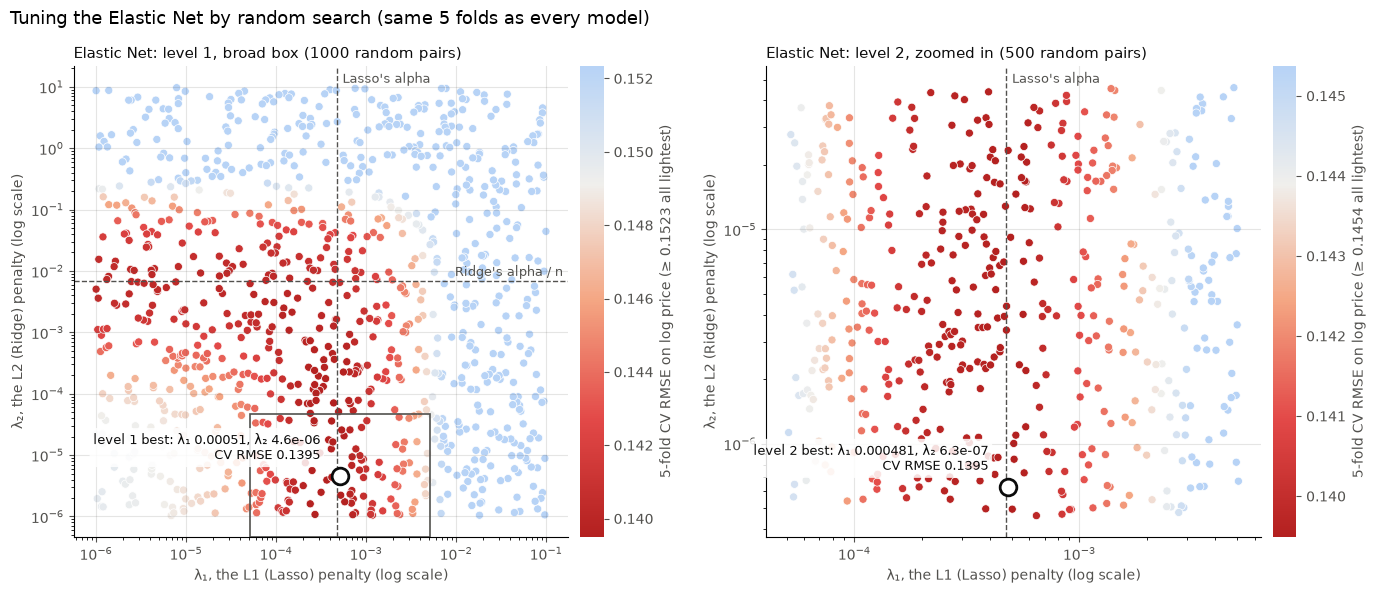

In [39]:
# tune (lambda_1, lambda_2) on all 1,460 training houses (the same 5 folds as every model): two-level random search
df_en_s1, df_en_s2, (en_l1, en_l2) = random_search_en(l_folds_all)
print(f'Elastic Net: best lambda_1 {en_l1:.3g}, lambda_2 {en_l2:.3g} (alpha {en_l1 + en_l2:.3g}, l1_ratio {en_l1 / (en_l1 + en_l2):.2f}), '
      f'CV RMSE there {pd.concat([df_en_s1, df_en_s2])["mean"].min():.4f} (the minimum over {sum(ui_en_n_draws)} noisy scores: optimistic)')

## chart: every random pair at (lambda_1, lambda_2), coloured by its CV RMSE (redder = lower). Left: level 1 (box = level 2's zoom). Right: level 2.
## Dashed guides = the pure models' own best penalties in these units: Lasso's alpha is a lambda_1; Ridge's alpha / n is a lambda_2
## (Ridge minimises RSS + alpha·|w|²; divided by 2n that is (1/2n)·RSS + ½·(alpha/n)·|w|²). Pure Lasso sits at lambda_2 = 0, below the chart; pure Ridge at lambda_1 = 0, left of it
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import Rectangle

cmap_en = LinearSegmentedColormap.from_list('cold_to_hot', ['#b3201f', '#e34948', '#f4a582', '#f0efec', '#b7d3f6'])  # hot red = lowest RMSE (best), light blue = worst
n_fit = np.mean([f['X_tr'].shape[0] for f in l_folds_all])  # training rows per fold, after the outlier drop
d_guides = {'lambda_1': (d_search['Lasso'][2], "Lasso's alpha"), 'lambda_2': (d_search['Ridge'][2] / n_fit, "Ridge's alpha / n")}
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, df_s, level, vmax in [(axes[0], df_en_s1, 'level 1', cv_naive_pp), (axes[1], df_en_s2, 'level 2', df_en_s2['mean'].quantile(0.9))]:
    df_s = df_s.sort_values('mean', ascending=False)  # best points drawn last, on top
    norm = Normalize(vmin=df_s['mean'].min(), vmax=vmax, clip=True)
    sc = ax.scatter(df_s['lambda_1'], df_s['lambda_2'], c=df_s['mean'], cmap=cmap_en, norm=norm, s=34, edgecolors='white', linewidths=0.5)
    cb = fig.colorbar(sc, ax=ax, pad=0.02)
    cb.set_label(f'5-fold CV RMSE on log price (≥ {vmax:.4f} all lightest)', color='#52514e')
    cb.ax.tick_params(colors='#52514e')
    cb.outline.set_visible(False)
    best = df_s.iloc[-1]
    ax.plot(best['lambda_1'], best['lambda_2'], 'o', color='#0b0b0b', markersize=12, markerfacecolor='white', markeredgewidth=2, zorder=3)
    ax.annotate(f"{level} best: λ₁ {best['lambda_1']:.3g}, λ₂ {best['lambda_2']:.2g}\nCV RMSE {best['mean']:.4f}", (best['lambda_1'], best['lambda_2']),
                xytext=(-14, 12), textcoords='offset points', ha='right', color='#0b0b0b', fontsize=9, bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='none', alpha=0.85))
    if df_s['lambda_1'].min() < d_guides['lambda_1'][0] < df_s['lambda_1'].max():  # guides only where the points are
        ax.axvline(d_guides['lambda_1'][0], color='#52514e', linestyle='--', linewidth=1)
        ax.annotate(d_guides['lambda_1'][1], (d_guides['lambda_1'][0], 1), xycoords=('data', 'axes fraction'), xytext=(4, -4), textcoords='offset points', va='top', color='#52514e', fontsize=9)
    if df_s['lambda_2'].min() < d_guides['lambda_2'][0] < df_s['lambda_2'].max():
        ax.axhline(d_guides['lambda_2'][0], color='#52514e', linestyle='--', linewidth=1)
        ax.annotate(d_guides['lambda_2'][1], (1, d_guides['lambda_2'][0]), xycoords=('axes fraction', 'data'), xytext=(-4, 4), textcoords='offset points', ha='right', color='#52514e', fontsize=9)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title(f"Elastic Net: {level}, {'broad box' if level == 'level 1' else 'zoomed in'} ({len(df_s)} random pairs)", loc='left', fontsize=11, color='#0b0b0b')
    ax.set_xlabel('λ₁, the L1 (Lasso) penalty (log scale)', color='#52514e')
    ax.set_ylabel('λ₂, the L2 (Ridge) penalty (log scale)', color='#52514e')
    ax.grid(color='#52514e', alpha=0.15, linewidth=0.8)
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(colors='#52514e')
lo1, hi1 = df_en_s2['lambda_1'].min(), df_en_s2['lambda_1'].max()
lo2, hi2 = df_en_s2['lambda_2'].min(), df_en_s2['lambda_2'].max()
axes[0].add_patch(Rectangle((lo1, lo2), hi1 - lo1, hi2 - lo2, fill=False, edgecolor='#52514e', linewidth=1.2))
fig.suptitle('Tuning the Elastic Net by random search (same 5 folds as every model)', x=0.01, ha='left', fontsize=13)
plt.tight_layout()
plt.show()

In [40]:
# honest CV RMSE (nested CV): the whole two-level random search is rerun inside each outer fold's 80% (on 5 inner folds of it),
# then the model is refit there at the pair it picked and scored on the outer 20%. This is the number to log and compare
cv_rmse('Elastic Net (log psf, all features)', fit_predict_en)

  Elastic Net: inner search picked lambda_1 0.000699, lambda_2 4.86e-07 (alpha 0.000699, l1_ratio 1.00)


/Users/jxwhaat/Documents/C - Library/BSE/1 - Courses/Term 1/22DM012 - Computational Machine Learning/Assignments/Assignment 01/22DM012-assn01-apartmentprices.nosync/.venv/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.178825e-02, tolerance: 6.693e-03
  model = cd_fast.enet_coordinate_descent_gram(


/Users/jxwhaat/Documents/C - Library/BSE/1 - Courses/Term 1/22DM012 - Computational Machine Learning/Assignments/Assignment 01/22DM012-assn01-apartmentprices.nosync/.venv/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.110269e-02, tolerance: 6.693e-03
  model = cd_fast.enet_coordinate_descent_gram(


  Elastic Net: inner search picked lambda_1 0.000521, lambda_2 0.000215 (alpha 0.000736, l1_ratio 0.71)


/Users/jxwhaat/Documents/C - Library/BSE/1 - Courses/Term 1/22DM012 - Computational Machine Learning/Assignments/Assignment 01/22DM012-assn01-apartmentprices.nosync/.venv/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.881453e-02, tolerance: 6.322e-03
  model = cd_fast.enet_coordinate_descent_gram(


...

Elastic Net: the level-1 best lambda_2 1.08e-06 is near the edge of the box, so the box should be extended


  Elastic Net: inner search picked lambda_1 0.000287, lambda_2 5.47e-07 (alpha 0.000288, l1_ratio 1.00)


  Elastic Net: inner search picked lambda_1 0.000324, lambda_2 5.9e-07 (alpha 0.000324, l1_ratio 1.00)


  Elastic Net: inner search picked lambda_1 4.39e-07, lambda_2 0.0107 (alpha 0.0107, l1_ratio 0.00)


,fold 1,fold 2,fold 3,fold 4,fold 5,mean,sd
"naive+ (psf, fs10, OLS)",0.1865,0.1491,0.1805,0.1598,0.1498,0.1651,0.0156
"naive++ (log psf, fs10, OLS)",0.1821,0.1336,0.1790,0.1275,0.1395,0.1523,0.0234
"Lasso (log psf, all features)",0.1667,0.1221,0.1662,0.1238,0.1232,0.1404,0.0213
"Ridge (log psf, all features)",0.1649,0.1224,0.1691,0.1248,0.1237,0.1410,0.0213
"Elastic Net (log psf, all features)",0.1665,0.1221,0.1662,0.1238,0.1239,0.1405,0.0211


In [41]:
# final model = (b): the pair from the random search on all 1,460 houses (the chart above), refit on all of them (outliers dropped)
d_model_pen['ElasticNet'] = refit_penalised('ElasticNet', en_l1 + en_l2, df_X_train, df_train['SalePrice'], l1_ratio=en_l1 / (en_l1 + en_l2))
d_pred_pen['ElasticNet'] = predict_penalised(d_model_pen['ElasticNet'], df_X_test)  # test-set sale prices

w = d_model_pen['ElasticNet'][-1].coef_
print(f"Elastic Net: lambda_1 {en_l1:.3g}, lambda_2 {en_l2:.3g}, {np.sum(w != 0)} of {w.size} coefficients non-zero, L2 norm {np.linalg.norm(w):.3f}")
print(f"test predictions: correlation with Lasso's {np.corrcoef(np.log(d_pred_pen['ElasticNet']), np.log(d_pred_pen['Lasso']))[0, 1]:.5f}, "
      f"with Ridge's {np.corrcoef(np.log(d_pred_pen['ElasticNet']), np.log(d_pred_pen['Ridge']))[0, 1]:.5f}")

Elastic Net: lambda_1 0.000481, lambda_2 6.31e-07, 103 of 268 coefficients non-zero, L2 norm 0.425
test predictions: correlation with Lasso's 1.00000, with Ridge's 0.99817


## Predict + export

### Kaggle scores (benchmarks)

Public leaderboard score = RMSE on log price (lower is better). Times are Barcelona local time (Kaggle reports UTC).

| Submitted | File | Model | 5-fold CV RMSE | Public score | Kaggle ref |
|---|---|---|---|---|---|
| 2026-10-25 01:54 | `sub01_ols-fs6_2026-10-25T0149.csv` | Naive: OLS on log price, 6 forward-selected numeric features, raw data | – | **0.15889** | 57609755 |
| 2026-10-27 00:50 | `sub02_olsplus-psf-fs10-avg_2026-10-27T0048.csv` | Naive+: OLS on price per sq ft, 10 forward-selected features from the cleaned, outlier-dropped, encoded data; 5-fold averaged weights | 0.161 | **0.15121** | 57681429 |
| 2026-10-27 19:44 | `sub03_olspp-logpsf-fs10-refit_2026-10-27T1944.csv` | Naive++: same procedure as naive+, but OLS on **log** price per sq ft; final model refit on 100% | 0.152 | **0.14903** | 57710595 |
| 2026-10-27 21:52 | `sub04_olspp-logpsf-fs10-fe-refit_2026-10-27T2152.csv` | Naive++ rerun: engineered features (`add_features`) + outliers dropped inside each fit (decision B); refit on 100% | 0.1403 (nested, all 1,460) | **0.14120** | 57712948 |
| 2026-10-27 21:52 | `sub05_lasso-logpsf-all_2026-10-27T2152.csv` | Lasso on log psf, all engineered features, α 0.000505; refit on 100% | 0.1272 (nested) | **0.12949** | 57712951 |
| 2026-10-27 21:52 | `sub06_ridge-logpsf-all_2026-10-27T2152.csv` | Ridge on log psf, all engineered features, α 21.6; refit on 100% | 0.1270 (nested) | **0.12450** | 57712953 |
| 2026-10-27 21:52 | `sub07_enet-logpsf-all_2026-10-27T2152.csv` | Elastic Net on log psf, all engineered features, λ₁ 0.000524, λ₂ 4.8e-07 (≈ Lasso); refit on 100% | 0.1278 (nested) | **0.12946** | 57712956 |

**CV evaluation changed on 2026-10-27 (outlier decision B).** The CV RMSEs in the table above were computed on the 1,442 houses left after the psf rule (outliers dropped *before* CV, so also missing from the validation folds). From now on, CV scores **all 1,460** training houses and the outliers are dropped inside each fit, from its training rows only; round 1 (huge partial sales 524, 1299) was added at the same time. Re-scored on the same 5 folds: **naive+ 0.1618 ± 0.018** and **naive++ 0.1532 ± 0.023**. The worst folds are 1 (0.186, holds 1299) and 3 (0.177–0.182, holds 524). These are the numbers to compare new models with. sub02/sub03 were made under the old procedure, which didn't drop 524 and 1299.

**Re-scored with the engineered features (2026-10-27, `add_features`: logs, 10 flags, log(1 + x) areas, `OverallQual_sq`), same 5 folds, all 1,460 houses, not resubmitted:** **naive+ 0.1493 ± 0.026** (was 0.1618; better in 4 of 5 folds) and **naive++ 0.1403 ± 0.030** (was 0.1532; better in all 5 folds). Folds 1 and 3 (which hold 1299 and 524) are still the worst, at about 0.177–0.186.

**Lasso and Ridge (2026-10-27, log psf, all engineered features, α tuned in two levels; not submitted):** nested CV **Lasso 0.1272 ± 0.033** (α ≈ 0.0005, 97 of 272 coefficients non-zero) and **Ridge 0.1270 ± 0.030** (α ≈ 21.6). Tuning-curve minima: 0.1266 and 0.1267. Both beat naive++ (0.1403) in all 5 folds. Lasso vs Ridge is within noise: Ridge wins folds 1 and 3 (the ones with 1299 and 524), Lasso wins folds 2, 4 and 5.

**Elastic Net (2026-10-27, log psf, all engineered features; not submitted):** (λ₁, λ₂) tuned by a two-level random search (1,000 + 500 log-uniform pairs). Nested CV **0.1278 ± 0.031**, so no better than Lasso or Ridge. The CV surface is a flat L-shaped valley: λ₁ ≈ Lasso's α with λ₂ ≈ 0, or λ₂ ≈ Ridge's α/n with λ₁ ≈ 0, both at about 0.1266–0.1268. On all 1,460 houses the search picked the Lasso end (λ₁ 0.000524, λ₂ 4.8e-07, `l1_ratio` 1.00, 94 of 272 non-zero), but 4 of the 5 outer folds' inner searches picked the Ridge end (`l1_ratio` ≈ 0). The extra hyperparameter adds selection noise without lowering the error.

**`GrLivArea` removed as a model input (2026-10-27, `ui_drop_grlivarea = True` in `add_features`; not submitted).** `log_GrLivArea` is gone; raw `GrLivArea` stays in `df_X` only for the target and the conversion back to price. Its parts `1stFlrSF` + `2ndFlrSF` + `LowQualFinSF` (= `GrLivArea` exactly) remain features. Re-scored, same 5 folds: naive+ 0.1550 ± 0.018 (was 0.1493), **naive++ 0.1452 ± 0.022** (was 0.1403), **Lasso 0.1255 ± 0.021** (was 0.1272; α 0.000392, 117 of 271 non-zero), **Ridge 0.1275 ± 0.022** (was 0.1270; α 6.48), **Elastic Net 0.1257 ± 0.021** (was 0.1278; λ₁ 0.000389, λ₂ 2.0e-06, `l1_ratio` 0.99 ≈ Lasso). Lasso now beats Ridge in all 5 folds. The Kaggle scores in the table above are for the earlier version, with `log_GrLivArea`.

**`1stFlrSF`, `2ndFlrSF`, `LowQualFinSF` also removed as model inputs (2026-10-27, `ui_drop_area_parts = True`; not submitted).** These sum to `GrLivArea` exactly, so no living-area measure is left (`has_2ndflr` stays). Re-scored, same 5 folds: naive+ 0.1651 ± 0.016, **naive++ 0.1523 ± 0.023** (was 0.1452), **Lasso 0.1404 ± 0.021** (was 0.1255; α 0.000474, 104 of 268 non-zero), **Ridge 0.1410 ± 0.021** (was 0.1275; α 7.75), **Elastic Net 0.1405 ± 0.021** (was 0.1257; `l1_ratio` 1.00 ≈ Lasso). Every model is worse by about 0.012–0.015.

In [42]:
datetime.now().strftime("%Y-%m-%dT%H%M")

'2026-10-27T2258'

In [43]:
export = False
ui_sub_name = 'sub01_ols-fs6_' + datetime.now().strftime("%Y-%m-%dT%H%M") # file name in submissions/ (no .csv)

if export:
    # predict SalePrice for test.csv with model_naive and export the Kaggle submission CSV    
    df_test = pd.read_csv(ROOT / "data" / "test.csv", **read_kwargs)

    ## features for the test set: same columns as the fit; fill NaNs with the TRAINING medians
    df_test_X = df_test[l_chosen].fillna(df_data[l_chosen].median())
    X_test = sm.add_constant(df_test_X, has_constant='add')

    ## predict log price, then transform back to price
    df_sub = pd.DataFrame({
        'Id': df_test['Id'],
        'SalePrice': np.exp(model_naive.predict(X_test)),
    })

    ## sanity checks before writing
    assert len(df_sub) == 1459 and df_sub['SalePrice'].notna().all()
    print(df_test[l_chosen].isna().sum()[lambda s: s > 0]) # which test NaNs got filled
    print(df_sub['SalePrice'].describe().round(0))

    path_sub = ROOT / "submissions" / f"{ui_sub_name}.csv"
    df_sub.to_csv(path_sub, index=False)
    print("saved", path_sub)

In [44]:
export_plus = False
ui_plus_version = 'avg'  # 'avg' = (a) averaged fold weights, 'refit' = (b) refit on 100%
ui_sub_name = f'sub02_olsplus-psf-fs10-{ui_plus_version}_' + datetime.now().strftime("%Y-%m-%dT%H%M")  # file name in submissions/ (no .csv)

if export_plus:
    # export the naive+ predictions for test.csv (computed in the naive+ section)
    df_sub = pd.DataFrame({
        'Id': df_test['Id'],
        'SalePrice': sl_pred_avg if ui_plus_version == 'avg' else sl_pred_refit,
    })

    ## sanity checks before writing
    assert len(df_sub) == 1459 and df_sub['SalePrice'].notna().all()
    print(df_sub['SalePrice'].describe().round(0))

    path_sub = ROOT / "submissions" / f"{ui_sub_name}.csv"
    df_sub.to_csv(path_sub, index=False)
    print("saved", path_sub)

In [45]:
export_pp = False
ui_sub_name = 'sub03_olspp-logpsf-fs10-refit_' + datetime.now().strftime("%Y-%m-%dT%H%M")  # file name in submissions/ (no .csv)

if export_pp:
    # export the naive++ predictions for test.csv (computed in the naive++ section)
    df_sub = pd.DataFrame({
        'Id': df_test['Id'],
        'SalePrice': sl_pred_pp,
    })

    ## sanity checks before writing
    assert len(df_sub) == 1459 and df_sub['SalePrice'].notna().all()
    print(df_sub['SalePrice'].describe().round(0))

    path_sub = ROOT / "submissions" / f"{ui_sub_name}.csv"
    df_sub.to_csv(path_sub, index=False)
    print("saved", path_sub)

In [46]:
export_v2 = False
ui_sub_stamp = datetime.now().strftime("%Y-%m-%dT%H%M")
d_sub_v2 = {  # file name in submissions/ (no .csv) -> test-set sale prices; all on log psf with the engineered features, final model (b)
    f'sub04_olspp-logpsf-fs10-fe-refit_{ui_sub_stamp}': sl_pred_pp,
    f'sub05_lasso-logpsf-all_{ui_sub_stamp}': d_pred_pen['Lasso'],
    f'sub06_ridge-logpsf-all_{ui_sub_stamp}': d_pred_pen['Ridge'],
    f'sub07_enet-logpsf-all_{ui_sub_stamp}': d_pred_pen['ElasticNet'],
}

if export_v2:
    # export naive++ (re-run with add_features + outlier decision B), Lasso, Ridge and Elastic Net in one go
    for sub_name, sl_pred in d_sub_v2.items():
        df_sub = pd.DataFrame({'Id': df_test['Id'], 'SalePrice': sl_pred})

        ## sanity checks before writing
        assert sl_pred.index.equals(df_test.index)  # same row order as test.csv
        assert len(df_sub) == 1459 and df_sub['SalePrice'].notna().all() and (df_sub['SalePrice'] > 0).all()
        print(sub_name, df_sub['SalePrice'].describe()[['mean', 'min', 'max']].round(0).to_dict())

        path_sub = ROOT / "submissions" / f"{sub_name}.csv"
        df_sub.to_csv(path_sub, index=False)
        print("saved", path_sub)

Another approach: let's try to predict price per square feet using the features, then use that to calculate our final predictions. 

Let's just compare a few features for a start. Just eyeballing, I'm gonna do an OLS with the following features, and with my intuition noted too: 
* `BldgType` - type of dwelling. This immediately stratifies the buyer base who may have very different economic conditions. 
* `YearBuilt` and `YearRemodAdd` - probably take the later of. Age of residence should have an impact on price (newer = better probably) but may require scaling; don't expect this to be a linear relationship. 
* `TotalBsmtSF` - maybe just start with a binary yes/no - I suspect houses with basements are different from houses without basements. 
* `CentralAir` - central air conditioning. Just because it's binary and it's easy ^_^
* `1stFlrSF`, `2ndFlrSF` - maybe enginner a total square footage? 
* `Bedroom`, `Kitchen`
* `GarageArea`
* `PoolArea`